# Expériences SMA — Brest

Validation 1940–2000, test verrouillé 2001–2025, puis étude finale 1940–2025. Ce notebook relit les résultats sauvegardés ; il n'entraîne aucun réseau et n'appelle pas le benchmark.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLAN_IMPLEMENTATION_MODELES_SMA.md").exists())
COMP = ROOT / "artifacts" / "competition"
FULL = ROOT / "artifacts" / "full_project"

def show_csv(path, rows=30):
    path = Path(path)
    if not path.exists():
        display(Markdown(f"**Artefact absent :** `{path.relative_to(ROOT)}`. Aucun résultat n'est revendiqué."))
        return pd.DataFrame()
    try:
        frame = pd.read_csv(path)
    except pd.errors.EmptyDataError:
        frame = pd.DataFrame()
    columns_by_name = {
        "validation_summary.csv": ["variable", "model", "crps", "twcrps", "coverage80", "width80", "bias", "brier", "fold_count"],
        "validation_mixture.csv": ["variable", "fold", "model", "tail_lambda", "crps", "twcrps"],
        "validation_individual.csv": ["variable", "fold", "model", "seed", "crps", "twcrps"],
        "test_diagnostics.csv": ["variable", "model", "crps", "twcrps", "coverage80", "width80", "bias", "brier"],
        "run_costs.csv": ["variable", "model_id", "fold", "seed", "steps", "best_step", "training_seconds", "gpu_memory_allocated_peak_bytes"],
        "residual_descriptive.csv": ["variable", "n", "skewness", "autocorrelation_lag1", "autocorrelation_lag2", "autocorrelation_lag3", "q05_C", "q50_C", "q95_C"],
        "bootstrap_dispersion.csv": ["variable", "model", "co2_ppm", "anchor_std_C", "generator_residual_std_C", "anchor_variance_fraction", "anchor_mean_shift_C"],
        "residual_law_diagnostics.csv": ["variable", "model", "mean_C", "std_C", "minimum_C", "q50_C", "maximum_C", "fraction_outside_central_window"],
        "bootstrap_block_sensitivity_summary.csv": ["variable", "model", "tail_lambda", "folds", "delta_crps_block1_minus3_C", "delta_twcrps_block1_minus3_C", "folds_global_block1_better", "folds_tail_block1_better"],
        "bootstrap_block_sensitivity_by_fold.csv": ["variable", "model", "fold", "tail_lambda", "delta_crps_block1_minus3_C", "delta_twcrps_block1_minus3_C"],
        "projection_summary.csv": ["variable", "scenario", "year", "co2", "q05", "q50", "q95", "event_probability"],
        "probability_40.csv": ["scenario", "k", "n", "probability", "ci_lower", "ci_upper", "resolution"],
        "trajectory_probability_40.csv": ["scenario", "k", "n", "probability", "ci_lower", "ci_upper"],
    }
    columns = [c for c in columns_by_name.get(path.name, frame.columns) if c in frame]
    display(frame[columns].head(rows).fillna("—"))
    display(Markdown(f"CSV complet : `{path.relative_to(ROOT)}`. Scores et largeurs en °C ; probabilités et couvertures sans unité."))
    if len(frame) > rows:
        display(Markdown(f"{len(frame)} lignes conservées dans le CSV complet."))
    return frame

def show_json(path):
    path = Path(path)
    if not path.exists():
        display(Markdown(f"**Artefact absent :** `{path.relative_to(ROOT)}`."))
        return {}
    record = json.loads(path.read_text(encoding="utf-8"))
    compact = record
    if path.name == "selection.json":
        compact = {key: record[key] for key in ("selected_models", "selected_tail_lambda", "final_steps") if key in record}
    elif path.name == "benchmark_results.json":
        compact = {"candidate": record.get("candidate"), "admissible_count": sum(bool(r.get("admissible")) for r in record.get("results", [])),
                   "results": [{"id": r.get("id"), "scores": r.get("scores"), "admissible": r.get("admissible"),
                                "errors": r.get("checks", {}).get("errors", [])} for r in record.get("results", [])]}
    display(Markdown("```json\n" + json.dumps(compact, ensure_ascii=False, indent=2) + "\n```"))
    display(Markdown(f"JSON complet : `{path.relative_to(ROOT)}`."))
    return record

def show_png(path):
    path = Path(path)
    if path.exists():
        display(Image(filename=str(path), width=1000))
    else:
        display(Markdown(f"**Figure absente :** `{path.relative_to(ROOT)}`."))

def show_figures(phase, names):
    for name in names:
        show_png(ROOT / "reports" / "figures" / phase / (name + ".png"))

def show_residuals(phase):
    display(Markdown(f"**Diagnostics résiduels descriptifs : phase {phase}.**"))
    frame = show_csv(ROOT / "artifacts" / phase / "annual_analysis" / "residual_descriptive.csv")
    if not frame.empty:
        import sys
        if str(ROOT / "src") not in sys.path:
            sys.path.insert(0, str(ROOT / "src"))
        from sma.reporting import residual_interpretation
        display(Markdown(residual_interpretation(frame)))
    return frame

def show_ddpm_failure():
    import sys
    if str(ROOT / "src") not in sys.path:
        sys.path.insert(0, str(ROOT / "src"))
    from sma.reporting import ddpm_failure_interpretation
    text = ddpm_failure_interpretation(ROOT)
    if text:
        text = text.replace("(diagnostic_echec_ddpm.md)", "(<" + (ROOT / "reports" / "diagnostic_echec_ddpm.md").as_posix() + ">)")
        display(Markdown(text))

def show_projected_events():
    path = FULL / "projection_summary.csv"
    if not path.exists():
        return show_csv(path)
    projected = pd.read_csv(path)
    columns = ["variable", "model", "scenario", "event_threshold_C", "event_probability", "event_definition", "n"]
    if {"year", *columns}.issubset(projected.columns):
        display(Markdown("**Probabilités marginales en 2100 :** Tmax > q80 ou Tmin < q20 de l’historique "
                         "1940–2025. Ces seuils descriptifs de la phase finale diffèrent des seuils de validation "
                         "et de test ajustés sur leurs trains. Les fréquences viennent des mêmes ensembles annuels "
                         "stockés, sans nouvelle simulation ; l’événement Tmax > 40 °C est présenté séparément."))
        display(projected.loc[projected.year == 2100, columns])
    return projected


## Audit, environnement et vérifications

In [2]:
audit = show_json(COMP / 'data_audit.json')
environment = show_json(COMP / 'environment.json')
tests = show_json(ROOT / 'artifacts' / 'test_results.json')

```json
{
  "yearly_temp_brest_train": {
    "rows": 61,
    "first": "1940-01-01 00:00:00",
    "last": "2000-01-01 00:00:00",
    "columns": [
      "valid_time",
      "max",
      "min",
      "co2"
    ],
    "missing": 0,
    "duplicate_dates": 0,
    "ranges": {
      "max": [
        21.685577392578125,
        30.38021850585937
      ],
      "min": [
        -6.604339599609375,
        2.195220947265625
      ],
      "co2": [
        310.0,
        388.0567043624922
      ]
    },
    "units": {
      "temperature": "°C fournis par le kit",
      "co2": "ppm fournis par le kit"
    },
    "sha256": "1f68ca45dda3527486c90d80b447918fc331dd13e30bd1841aa12d85f6752e5d"
  },
  "daily_temp_brest_train": {
    "rows": 22281,
    "first": "1940-01-01 00:00:00",
    "last": "2000-12-31 00:00:00",
    "columns": [
      "valid_time",
      "mean"
    ],
    "missing": 0,
    "duplicate_dates": 0,
    "ranges": {
      "mean": [
        -5.2373046875,
        25.00531005859375
      ]
    },
    "units": {
      "temperature": "°C fournis par le kit",
      "co2": "ppm fournis par le kit"
    },
    "sha256": "c21b20ce2477c88ccc4f9884691deb42bb59001b220724dfdf31d41a76ddeb4b"
  },
  "test_inputs": {
    "rows": 25,
    "first": "2001-01-01 00:00:00",
    "last": "2025-01-01 00:00:00",
    "columns": [
      "valid_time",
      "co2"
    ],
    "missing": 0,
    "duplicate_dates": 0,
    "ranges": {
      "co2": [
        389.51191700385147,
        428.5017353613867
      ]
    },
    "units": {
      "temperature": "°C fournis par le kit",
      "co2": "ppm fournis par le kit"
    },
    "sha256": "3aaddab34d0b54c60dea7835d48dac9b5f9b477a993e95648dee12af88a1e184"
  },
  "yearly_future_co2": {
    "rows": 75,
    "first": "2026-01-01 00:00:00",
    "last": "2100-01-01 00:00:00",
    "columns": [
      "valid_time",
      "ssp1-2.6",
      "ssp2-4.5",
      "ssp5-8.5"
    ],
    "missing": 0,
    "duplicate_dates": 0,
    "ranges": {
      "ssp1-2.6": [
        400.0,
        435.8123975032748
      ],
      "ssp2-4.5": [
        420.18854219474224,
        526.9873843407519
      ],
      "ssp5-8.5": [
        421.1216772259265,
        946.2221518449436
      ]
    },
    "units": {
      "temperature": "°C fournis par le kit",
      "co2": "ppm fournis par le kit"
    },
    "sha256": "c39c3402b505eddbca00a00f50ae64c258c3b6e872ae8313db896d7233e8a0b5"
  },
  "data_limits": "Températures moyennes journalières distinctes des extrêmes annuels; provenance ERA5 et résolution non certifiées par ces CSV."
}
```

JSON complet : `artifacts\competition\data_audit.json`.

```json
{
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "executable": "C:\\Users\\edlas\\AppData\\Local\\Programs\\Python\\Python312\\python.exe",
  "platform": "Windows-11-10.0.26300-SP0",
  "packages": {
    "torch": "2.5.1+cu121",
    "numpy": "2.3.5",
    "pandas": "2.3.3",
    "scipy": "1.16.3",
    "matplotlib": "3.10.8",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.2.0",
    "PyYAML": "6.0.2",
    "pytest": "9.0.2"
  },
  "cuda": "12.1",
  "cuda_available": true,
  "gpu": "NVIDIA GeForce GTX 1660 Ti",
  "dtype": "float32",
  "amp": false,
  "commit": null,
  "timestamp_utc": "2026-10-08T13:00:55Z"
}
```

JSON complet : `artifacts\competition\environment.json`.

```json
{
  "command": "python -m pytest -q",
  "exit_code": 0,
  "passed": 38,
  "subtests_passed": 4,
  "pytest_seconds": 26.93,
  "phase": "before_test_truth",
  "notes": "Tests synthétiques, aucune vérité climatique ouverte; scores, folds, bootstrap, kit, extraction, DDPM/DDM, reprise et interruption fidèle, sentinelle et empreintes, calendrier bissextile et diagnostics."
}
```

JSON complet : `artifacts\test_results.json`.

## Entraînements de contrôle réellement exécutés

Les smokes détectent les erreurs d'implémentation ; leurs scores ne sont pas les résultats définitifs de la compétition.

In [3]:
smoke = show_json(ROOT / 'artifacts' / 'smoke' / 'summary.json')

```json
{
  "status": "completed",
  "climate": [
    {
      "model_id": "D0_ddpm",
      "variable": "max",
      "fold": "F1",
      "steps": 100,
      "best_step": 100,
      "validation_crps": 2.291495873569444,
      "residual_mean": 4.556484361905139,
      "residual_std": 10.622632719444397,
      "training_seconds": 1.8098876000149176,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "C0_direct_crps",
      "variable": "max",
      "fold": "F1",
      "steps": 100,
      "best_step": 100,
      "validation_crps": 1.1899467129231938,
      "residual_mean": -0.04466771337389946,
      "residual_std": 0.9797835342899393,
      "training_seconds": 1.4649259999860078,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "D1_ddm_crps",
      "variable": "max",
      "fold": "F1",
      "steps": 100,
      "best_step": 100,
      "validation_crps": 1.1856801851080383,
      "residual_mean": 0.03055888219550252,
      "residual_std": 1.114270679906182,
      "training_seconds": 1.119170000019949,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "D2_ddm_tail",
      "variable": "max",
      "fold": "F1",
      "steps": 100,
      "best_step": 100,
      "validation_crps": 1.1847316091910893,
      "residual_mean": 0.013020559541881084,
      "residual_std": 1.1195759505917382,
      "training_seconds": 1.4637058000080287,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "D0_ddpm",
      "variable": "min",
      "fold": "F1",
      "steps": 100,
      "best_step": 100,
      "validation_crps": 1.2603098470618692,
      "residual_mean": 0.29185124033410104,
      "residual_std": 2.327237098205127,
      "training_seconds": 1.1476842000265606,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "C0_direct_crps",
      "variable": "min",
      "fold": "F1",
      "steps": 100,
      "best_step": 50,
      "validation_crps": 0.9400668145977565,
      "residual_mean": 0.16253279626742007,
      "residual_std": 0.6215730837647575,
      "training_seconds": 1.015354999981355,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "D1_ddm_crps",
      "variable": "min",
      "fold": "F1",
      "steps": 100,
      "best_step": 50,
      "validation_crps": 0.9317469650222655,
      "residual_mean": 0.13735877764597534,
      "residual_std": 0.7582585600218805,
      "training_seconds": 1.0041854999726638,
      "device": "cuda",
      "finite": true
    },
    {
      "model_id": "D2_ddm_tail",
      "variable": "min",
      "fold": "F1",
      "steps": 100,
      "best_step": 50,
      "validation_crps": 0.9365316598486169,
      "residual_mean": 0.1252539883889258,
      "residual_std": 0.7708002332983453,
      "training_seconds": 1.3686789000057615,
      "device": "cuda",
      "finite": true
    }
  ],
  "synthetic": [
    {
      "model_id": "D0_ddpm",
      "distribution": "N(0,1)",
      "training_n": 2048,
      "independent_evaluation_n": 1024,
      "steps": 1500,
      "sample_n": 10000,
      "mean": 0.010194451312488672,
      "std": 1.0821361932883975,
      "q01": -2.344557933807373,
      "q99": 2.5245509338378924,
      "evaluation_crps": 0.5489017530649816,
      "oracle_mc_crps": 0.5459707351583869,
      "collapsed_zero_crps": 0.7679933755321378,
      "recovery_diagnostic_passed": true,
      "training_seconds": 14.64656239998294,
      "inference_seconds": 0.4736731000011787,
      "device": "cuda"
    },
    {
      "model_id": "C0_direct_crps",
      "distribution": "N(0,1)",
      "training_n": 2048,
      "independent_evaluation_n": 1024,
      "steps": 1500,
      "sample_n": 10000,
      "mean": -0.043321676403656605,
      "std": 1.003201528603114,
      "q01": -2.2931151270866392,
      "q99": 2.306228697299958,
      "evaluation_crps": 0.5463574979603,
      "oracle_mc_crps": 0.5459707351583869,
      "collapsed_zero_crps": 0.7679933755321378,
      "recovery_diagnostic_passed": true,
      "training_seconds": 13.023891100019682,
      "inference_seconds": 0.010868599987588823,
      "device": "cuda"
    },
    {
      "model_id": "D1_ddm_crps",
      "distribution": "N(0,1)",
      "training_n": 2048,
      "independent_evaluation_n": 1024,
      "steps": 1500,
      "sample_n": 10000,
      "mean": -0.11418694743178785,
      "std": 1.2508464345657846,
      "q01": -2.946530373096466,
      "q99": 2.7676547884941103,
      "evaluation_crps": 0.5600443847712806,
      "oracle_mc_crps": 0.5459707351583869,
      "collapsed_zero_crps": 0.7679933755321378,
      "recovery_diagnostic_passed": true,
      "training_seconds": 12.97880380001152,
      "inference_seconds": 0.009381400013808161,
      "device": "cuda"
    },
    {
      "model_id": "D2_ddm_tail",
      "distribution": "N(0,1)",
      "training_n": 2048,
      "independent_evaluation_n": 1024,
      "steps": 1500,
      "sample_n": 10000,
      "mean": -0.15046964015997946,
      "std": 1.2573937588451578,
      "q01": -3.003621895313263,
      "q99": 2.744304959774018,
      "evaluation_crps": 0.5626540157713563,
      "oracle_mc_crps": 0.5459707351583869,
      "collapsed_zero_crps": 0.7679933755321378,
      "recovery_diagnostic_passed": true,
      "training_seconds": 18.666219600010663,
      "inference_seconds": 0.008733100024983287,
      "device": "cuda"
    }
  ],
  "elapsed_seconds": 6.563310300000012,
  "gpu": "NVIDIA GeForce GTX 1660 Ti",
  "interpretation": "100-step climate runs test execution only; known-normal runs diagnose ability to learn and ancestral/endpoint sampling. These are not climate validation results.",
  "failures": []
}
```

JSON complet : `artifacts\smoke\summary.json`.


## Méthodes et conventions mathématiques

L'ancre est ajustée séparément pour Tmax et Tmin : $Y=a+b\log(C)+R$, avec $b=\max(b_{OLS},0)$,
$a=\overline{Y-b\log(C)}$, $\sigma=\mathrm{sd}(R,ddof=2)$ et $Z=R/\sigma$. Le CO₂ est exprimé
en ppm et les résultats en °C. La contrainte traduit ici une hypothèse de tendance locale monotone.
Elle ne démontre pas une réponse physique universelle. La loi résiduelle est supposée stationnaire.

R0 utilise $R\sim\mathcal N(0,\sigma^2)$ ; R1 ajuste une GEV à R pour Tmax, à −R pour Tmin,
avec la convention SciPy $c=-\xi$. R2 rééchantillonne les résidus. Le support GEV et les échecs
d'admissibilité doivent être examinés même si le score moyen semble favorable.
La reproduction exacte R0_exact suit les quatre appels RNG originaux
(test_max, test_min, proj_max, proj_min) : ses résidus sont indépendants entre scénarios.
Les autres exports réutilisent les mêmes résidus et, lorsqu'elle varie, la même ancre entre scénarios.

Le DDPM D0 apprend le bruit dans $Z_k=\sqrt{\bar\alpha_k}Z+\sqrt{1-\bar\alpha_k}\epsilon$ par MSE,
avec 100 pas et un calendrier cosinus. Sa génération suit le processus ancestral inverse. D1 produit
$\hat Z_m=g_\phi(u,t,\zeta_m)$ avec $u=(1-t)Z+t\epsilon$. Dans un ensemble d'entraînement,
u et t sont communs, les latents $\zeta_m$ indépendants ; l'inférence utilise t=1, sans observation
future. C0 emploie le même générateur avec u=0, t=1, pour mesurer l'apport du débruitage auxiliaire.
Il s'agit d'une adaptation scalaire d'une méthode météorologique récente, et non d'une validation
de cette publication sur Brest.

Pour D0, $L_{MSE}=\mathbb E[(\epsilon-\epsilon_\phi(Z_k,k/K))^2]$. En génération :

$$
Z_{k-1}=\frac{1}{\sqrt{\alpha_k}}\left(Z_k-
\frac{\beta_k}{\sqrt{1-\bar\alpha_k}}\epsilon_\phi(Z_k,k/K)\right)
+\sqrt{\tilde\beta_k}\eta,\qquad
\tilde\beta_k=\beta_k\frac{1-\bar\alpha_{k-1}}{1-\bar\alpha_k}.
$$

Le dernier pas ne rajoute aucun bruit. Le calendrier cosinus utilise s=0,008, beta ≤ 0,999,
et son alpha_bar terminal est inférieur à 10⁻³. Les calendriers sont dans les checkpoints.

Le CRPS d'évaluation est $N^{-1}\sum_m|x_m-y|-(2N^2)^{-1}\sum_{m,n}|x_m-x_n|$,
calculé par tri en float64. L'apprentissage C0/D1/D2 utilise M=32 et
$afCRPS=0.95\,fCRPS+0.05\,CRPS_{emp}$, où le terme de dispersion fair a le dénominateur
$2M(M-1)$. Ce petit mélange est légèrement biaisé et diffère du score empirique officiel.
D2 ajoute $\lambda\,afCRPS(h(\hat Y),h(Y))$, avec la même convention
$afCRPS=0.95\,fCRPS+0.05\,CRPS_{emp}$ que le terme global, et
$h(x)=\max(x,s_{hot})$ pour Tmax et
$h(x)=\min(x,s_{cold})$ pour Tmin. Ces seuils sont les quantiles 0,80/0,20 du train.
Le twCRPS d'évaluation applique seulement cette transformation au calcul du score : aucun tirage
de température n'est écrêté. Toutes les années comptent, y compris les fausses alertes.

D3 et D4 réutilisent les réseaux de D1/D2 et ajoutent un bootstrap résiduel de l'ancre à CO₂ fixé
(500 réplications, blocs circulaires de 3 ans ; sensibilité longueur 1). L'échelle et la loi neuronale
restent fixes : cette approximation ne mesure pas toute l'incertitude des paramètres. Elle n'est pas
un posterior bayésien. Le même couple ancre/résidu est employé entre scénarios d'une année.

La contrainte $b\geq0$ peut aussi décaler la moyenne des ancres bootstrap vers le haut lors de
l'extrapolation. L'ajout n'agit donc pas seulement sur la largeur : le tableau de dispersion
rapporte également le décalage moyen par rapport à l'ancre ponctuelle. Un gain de CRPS ne
doit pas être attribué automatiquement à la seule représentation de l'incertitude.

Les intervalles sont centraux, à 50/80/90 %, avec couverture inclusive et largeur en °C.
Le PIT est $(\#\{x_m<y\}+0.5\#\{x_m=y\})/N$, un rang médian déterministe adapté aux égalités
de R2. Le Brier utilise les événements stricts Tmax>s ou Tmin<s. Le biais est la moyenne de
$E_F(Y)-y$, la MAE celle de la médiane. Un PIT de 25 points ne certifie pas une calibration.

## Portée physique et limites

Les températures moyennes journalières servent aux vagues de chaleur ; leurs maxima ne remplacent
pas les extrêmes horaires du fichier annuel. Les 61 puis 86 années restent le nombre d'observations
annuelles : le bruit d'entraînement et 10 000 simulations n'ajoutent aucune observation climatique.
Le CO₂ décrit une tendance mondiale et ne suffit pas à établir une causalité locale complète :
variabilité atmosphérique et océanique, autres forçages et état local ne sont pas explicitement modélisés.

Un bon CRPS sur 25 années évalue surtout la loi dans la région observée. Il ne valide pas la queue
à 40 °C, ni l'extrapolation jusqu'à un CO₂ très supérieur au domaine historique. Les paramètres GEV,
la stationnarité résiduelle et la forme log-linéaire sont fragiles avec ce petit échantillon. Les bornes
du kit et ses tests de monotonie/largeur sont des conventions du groupe, pas des lois physiques.

Il faut distinguer : erreur Monte-Carlo (nombre fini de simulations, conditionnel au modèle ajusté),
incertitude d'estimation (ancre et poids appris) et erreur de modèle (tendance, queue, dynamique).
Le bootstrap d'ancre ne traite que la première composante paramétrique de la tendance.
Une probabilité d'au moins un dépassement durant 2026–2100 exige une hypothèse de dépendance :
résidus indépendants conditionnellement à l'ancre, avec la même ancre conservée sur la trajectoire.
La formule $1-\prod_t(1-p_t)$ pour des marges n'est pas valide avec une ancre aléatoire partagée.


## Validation temporelle et ablations

Le CRPS du mélange de graines est calculé directement sur ses tirages. La moyenne des CRPS individuels n'est pas ce score. Les seuils et ancres sont ajustés sur le train de chaque fold.

In [4]:
validation = show_csv(COMP / 'validation_summary.csv')
folds = show_csv(COMP / 'validation_mixture.csv', 60)
seeds = show_csv(COMP / 'validation_individual.csv', 30)

,variable,model,crps,twcrps,coverage80,width80,bias,brier,fold_count
0,max,C0_direct_crps,1.142265,0.403289,0.733333,5.144457,-0.206869,0.166280,3
1,max,D0_ddpm,1.097160,0.389177,0.766667,5.140041,-0.273135,0.153721,3
2,max,D1_ddm_crps,1.120387,0.386446,0.800000,5.492069,-0.113684,0.155856,3
3,max,D2_ddm_tail_lambda0.5,1.121605,0.385844,0.800000,5.515968,-0.128532,0.155961,3
4,max,D2_ddm_tail_lambda1,1.125073,0.386949,0.800000,5.447067,-0.149970,0.155696,3
5,max,D2_ddm_tail_lambda2,1.141764,0.391472,0.800000,5.632326,-0.227321,0.158266,3
6,max,D3_ddm_anchor,1.110931,0.378243,0.833333,5.651930,0.079950,0.156330,3
7,max,D4_ddm_tail_anchor_lambda0.5,1.111625,0.377714,0.833333,5.677580,0.065102,0.156210,3
8,max,D4_ddm_tail_anchor_lambda1,1.114176,0.378202,0.800000,5.621393,0.043664,0.155756,3
9,max,D4_ddm_tail_anchor_lambda2,1.127501,0.382432,0.800000,5.799409,-0.033687,0.158433,3


CSV complet : `artifacts\competition\validation_summary.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,variable,fold,model,tail_lambda,crps,twcrps
0,max,F1,R0_gaussian,0.0,1.189461,0.412457
1,max,F1,R1_gev,0.0,1.185812,0.411326
2,max,F1,R2_empirical,0.0,1.176903,0.401202
3,max,F1,D0_ddpm,0.0,1.180557,0.403257
4,max,F1,C0_direct_crps,0.0,1.173402,0.397608
5,max,F1,D1_ddm_crps,0.0,1.178647,0.399509
6,max,F1,D2_ddm_tail_lambda0.5,0.5,1.179057,0.399745
7,max,F1,D2_ddm_tail_lambda1,1.0,1.179183,0.402187
8,max,F1,D2_ddm_tail_lambda2,2.0,1.179521,0.401183
9,max,F1,D3_ddm_anchor,0.0,1.194354,0.397810


CSV complet : `artifacts\competition\validation_mixture.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

78 lignes conservées dans le CSV complet.

,variable,fold,model,seed,crps,twcrps
0,max,F1,R0_gaussian,stat,1.189461,0.412457
1,max,F1,R1_gev,stat,1.185812,0.411326
2,max,F1,R2_empirical,stat,1.176903,0.401202
3,max,F1,D0_ddpm,0,1.181837,0.403725
4,max,F1,D0_ddpm,1,1.181749,0.400753
5,max,F1,D0_ddpm,2,1.184787,0.407823
6,max,F1,C0_direct_crps,0,1.176444,0.400658
7,max,F1,C0_direct_crps,1,1.174394,0.396973
8,max,F1,C0_direct_crps,2,1.174013,0.397524
9,max,F1,D1_ddm_crps,0,1.177547,0.398387


CSV complet : `artifacts\competition\validation_individual.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

198 lignes conservées dans le CSV complet.

In [5]:
if not validation.empty:
    for variable in ['max', 'min']:
        view = validation[validation.variable == variable].sort_values('crps')
        neural = view[view.model.astype(str).str.startswith(('D', 'C0'))]
        if not view.empty and not neural.empty:
            best = neural.iloc[0]
            display(Markdown(f'Pour T{variable}, la meilleure variante neuronale en validation est **{best.model}**, CRPS {best.crps:.6f} °C ; écart au meilleur score toutes familles {best.crps - view.iloc[0].crps:+.6f} °C. La méthode reste expliquée même si une référence statistique est retenue.'))

Pour Tmax, la meilleure variante neuronale en validation est **D0_ddpm**, CRPS 1.097160 °C ; écart au meilleur score toutes familles +0.000000 °C. La méthode reste expliquée même si une référence statistique est retenue.

Pour Tmin, la meilleure variante neuronale en validation est **D0_ddpm**, CRPS 1.143005 °C ; écart au meilleur score toutes familles +0.000000 °C. La méthode reste expliquée même si une référence statistique est retenue.

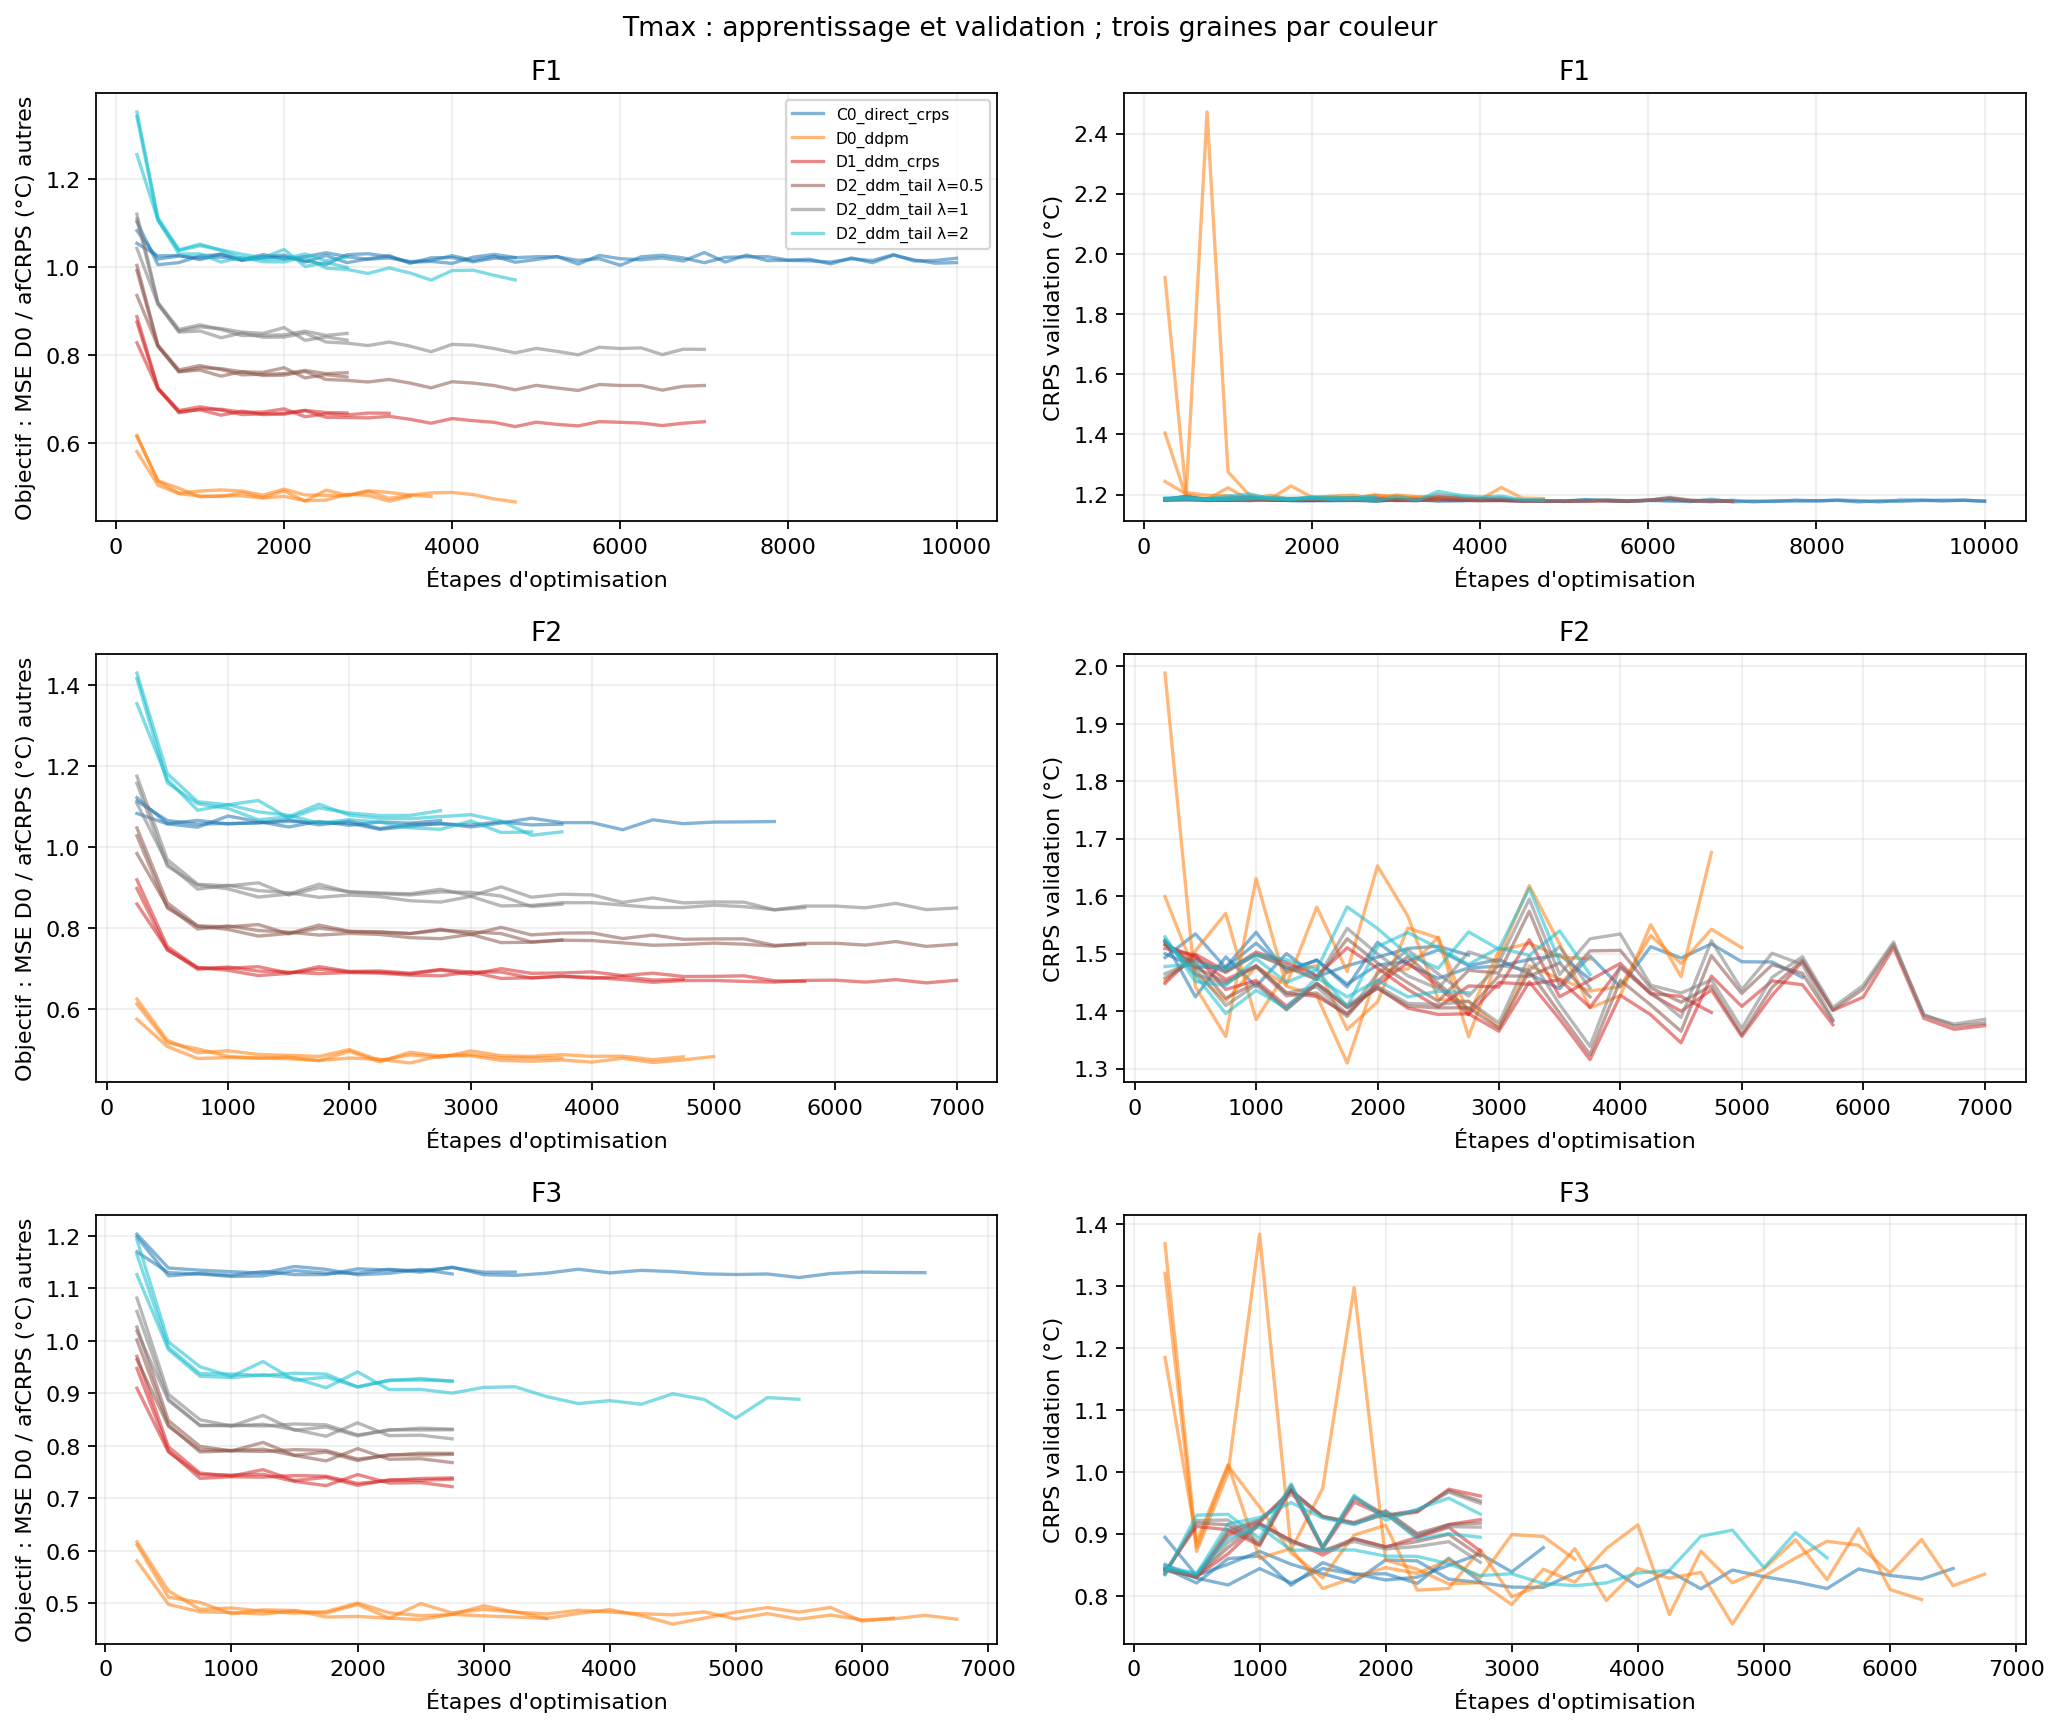

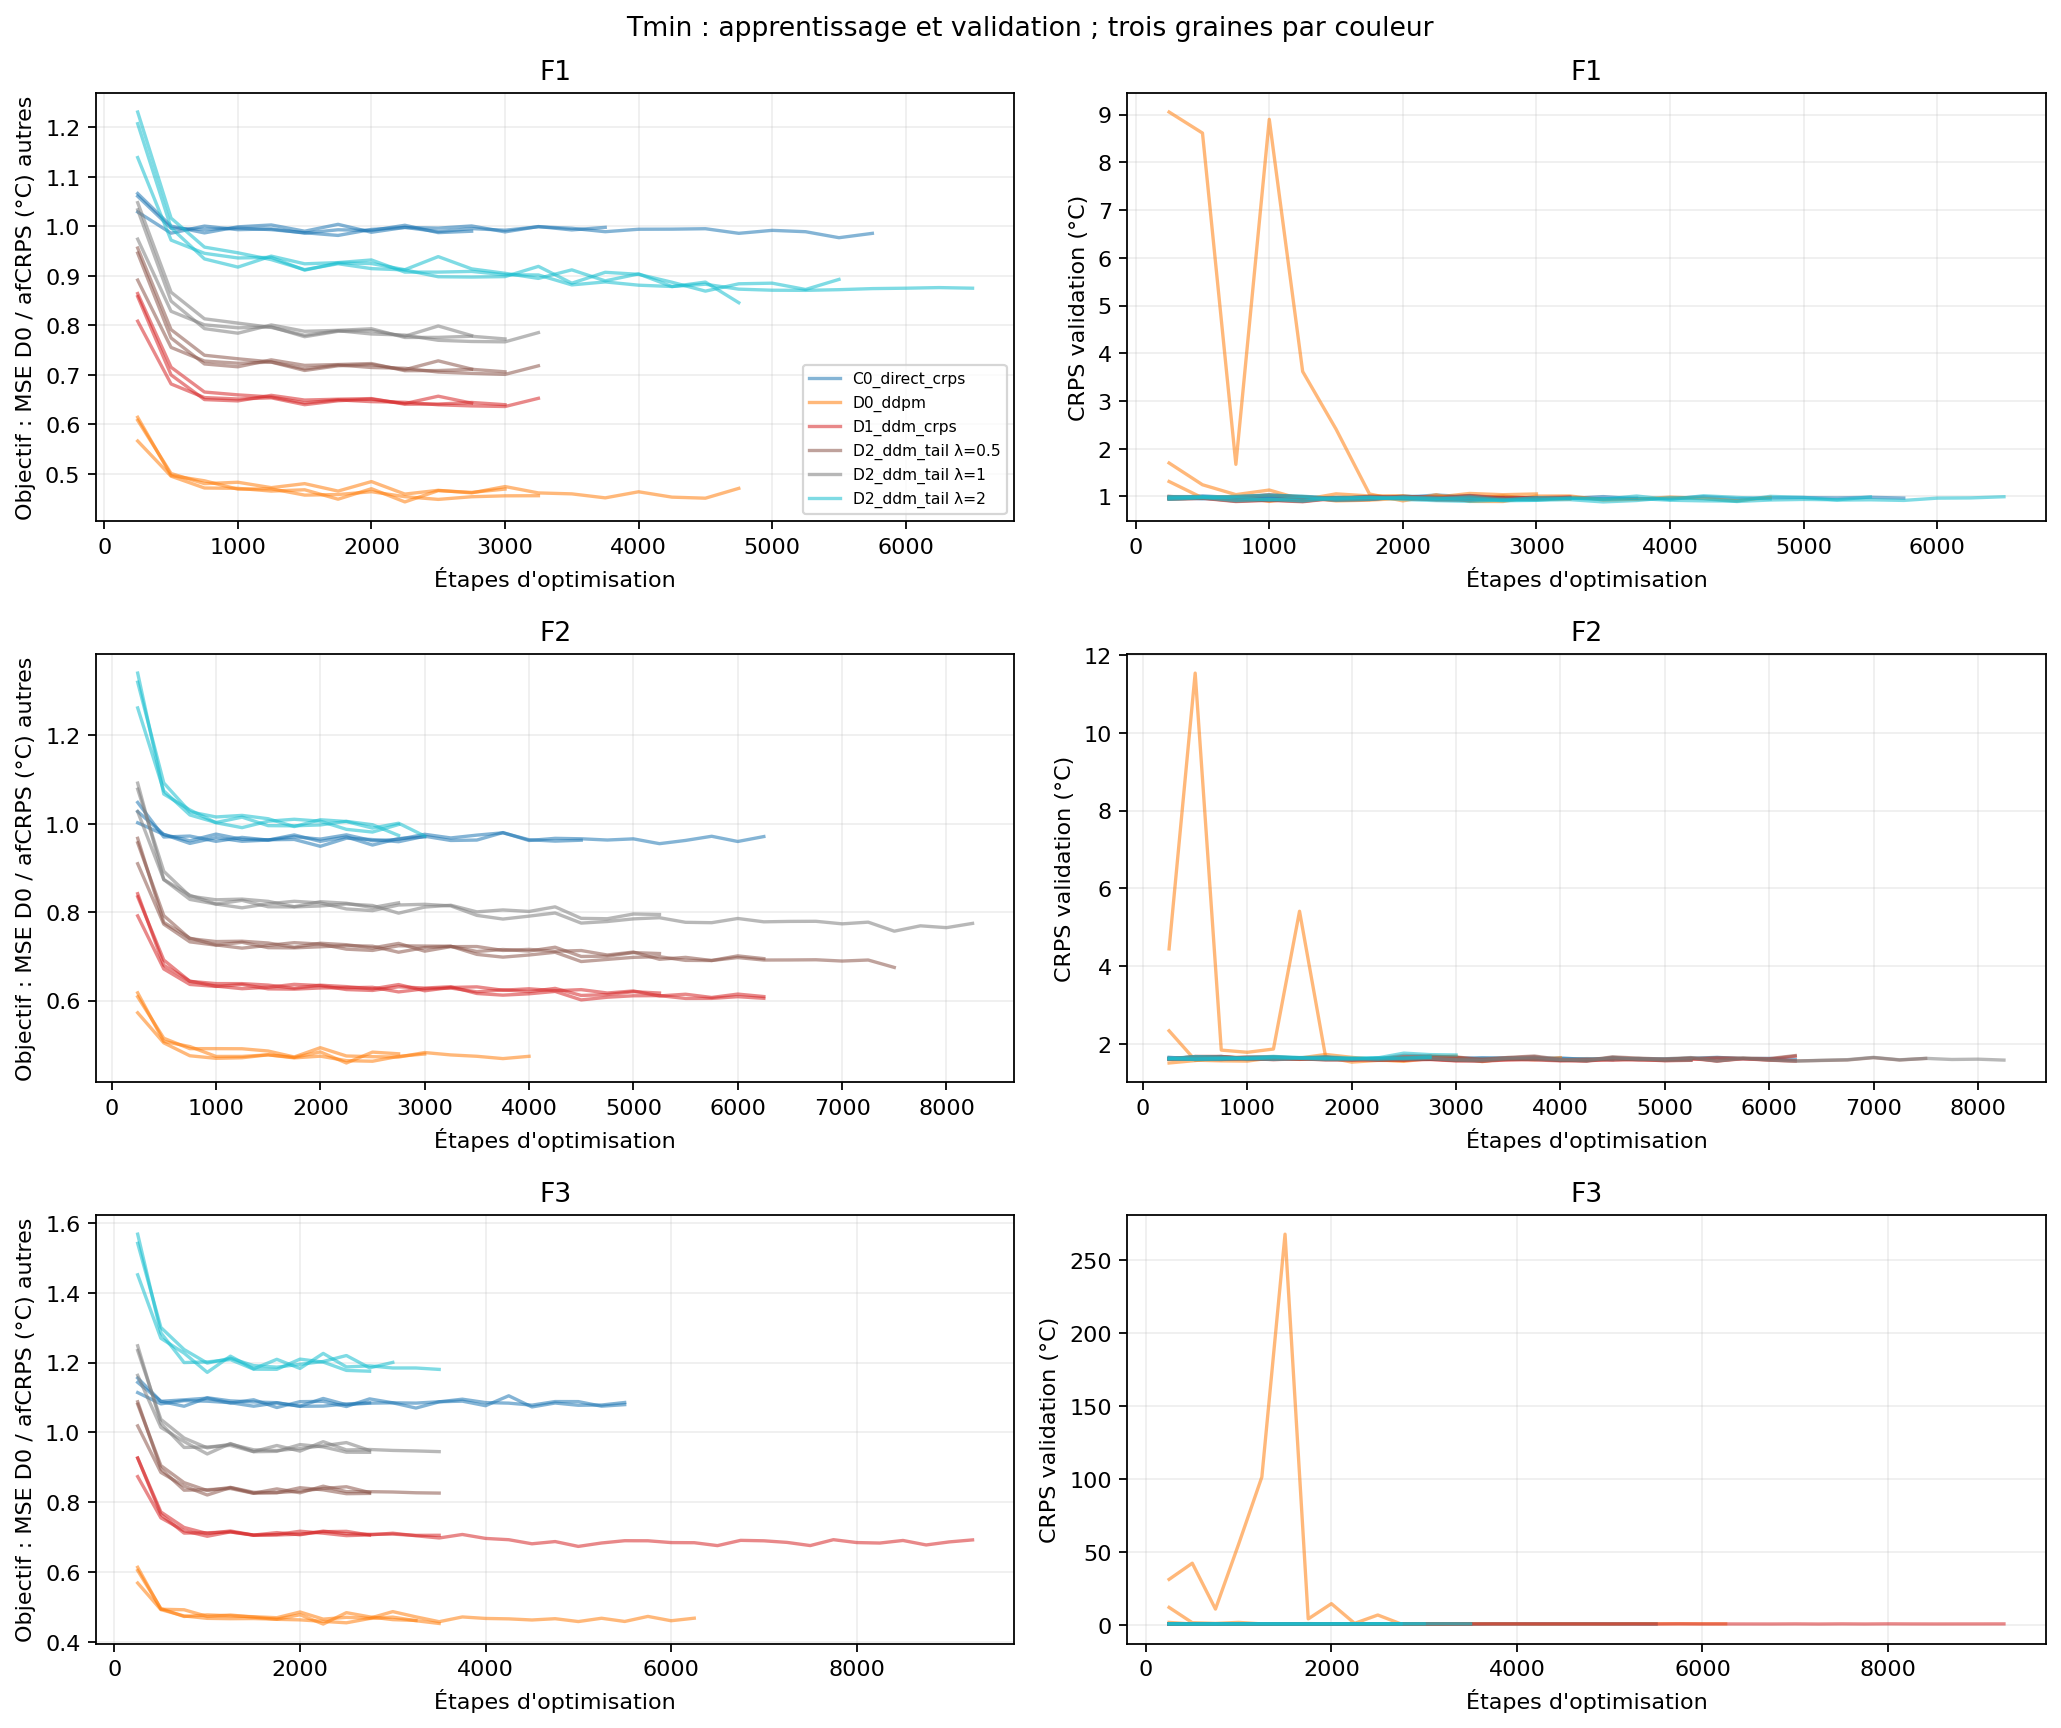

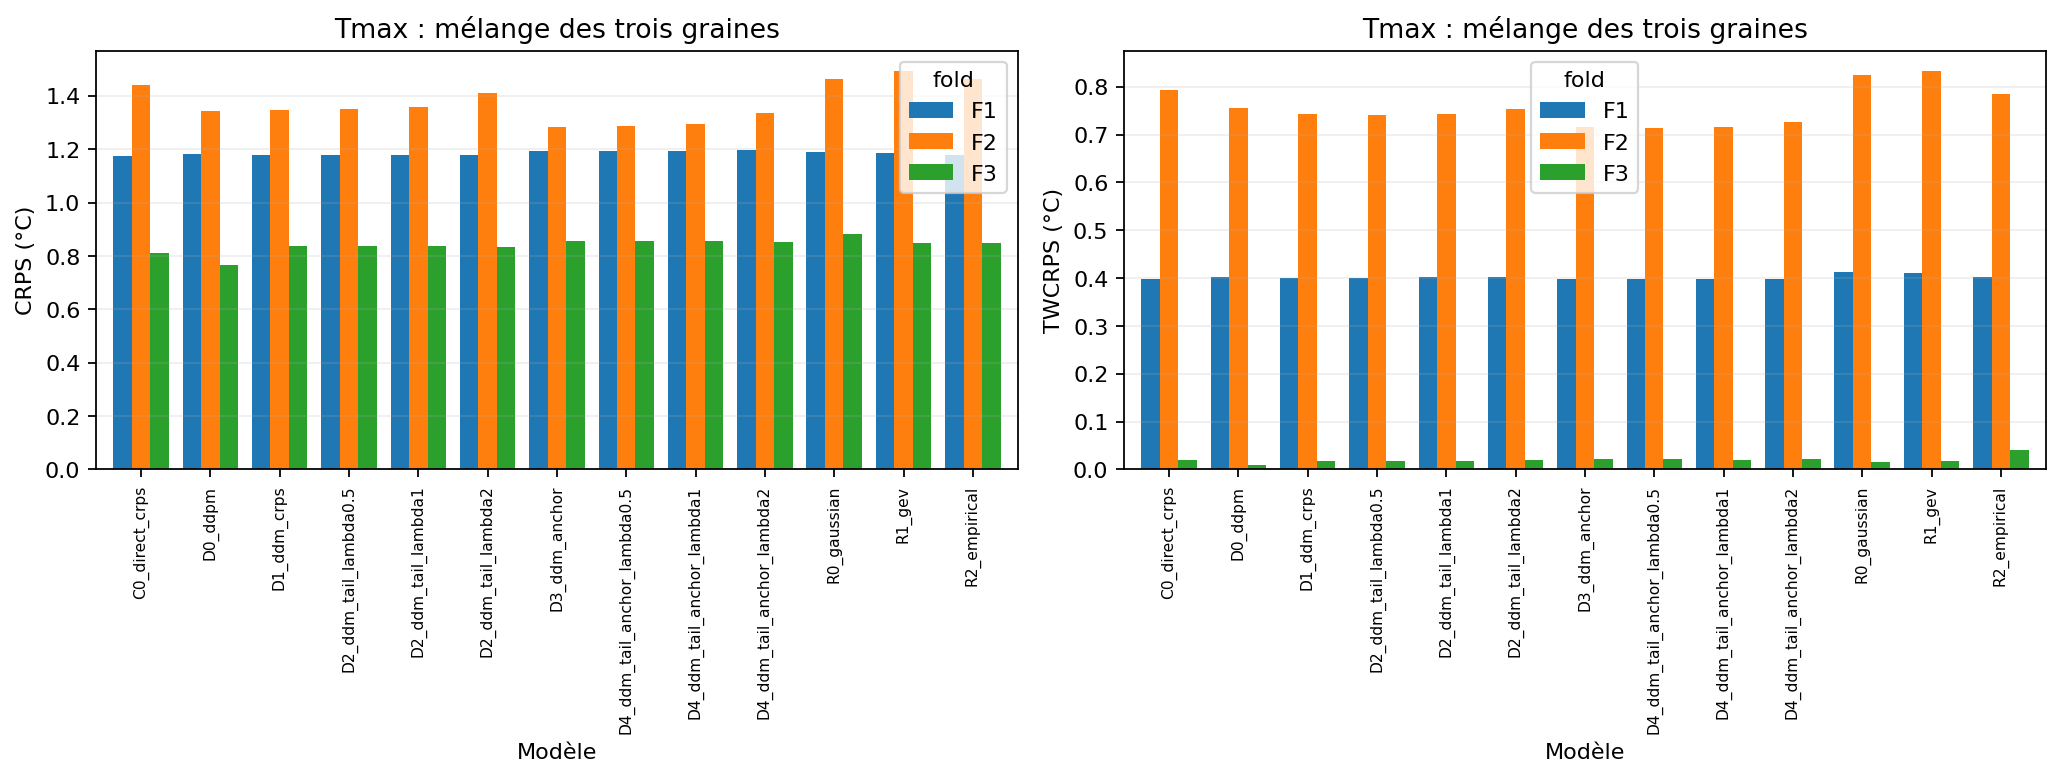

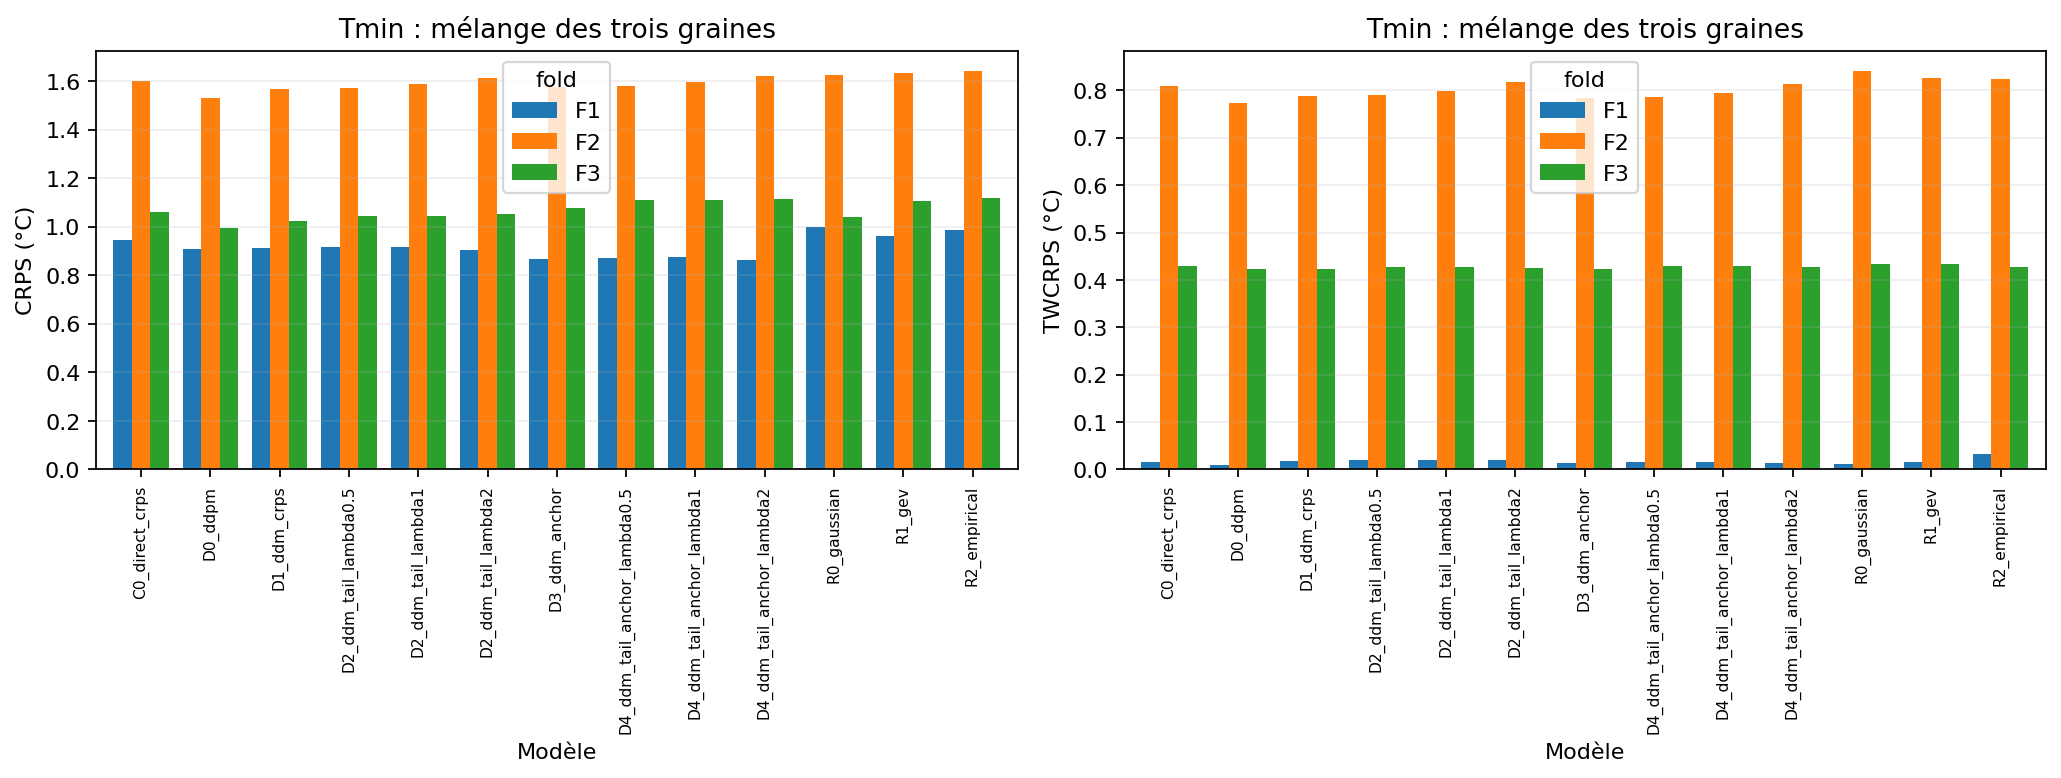

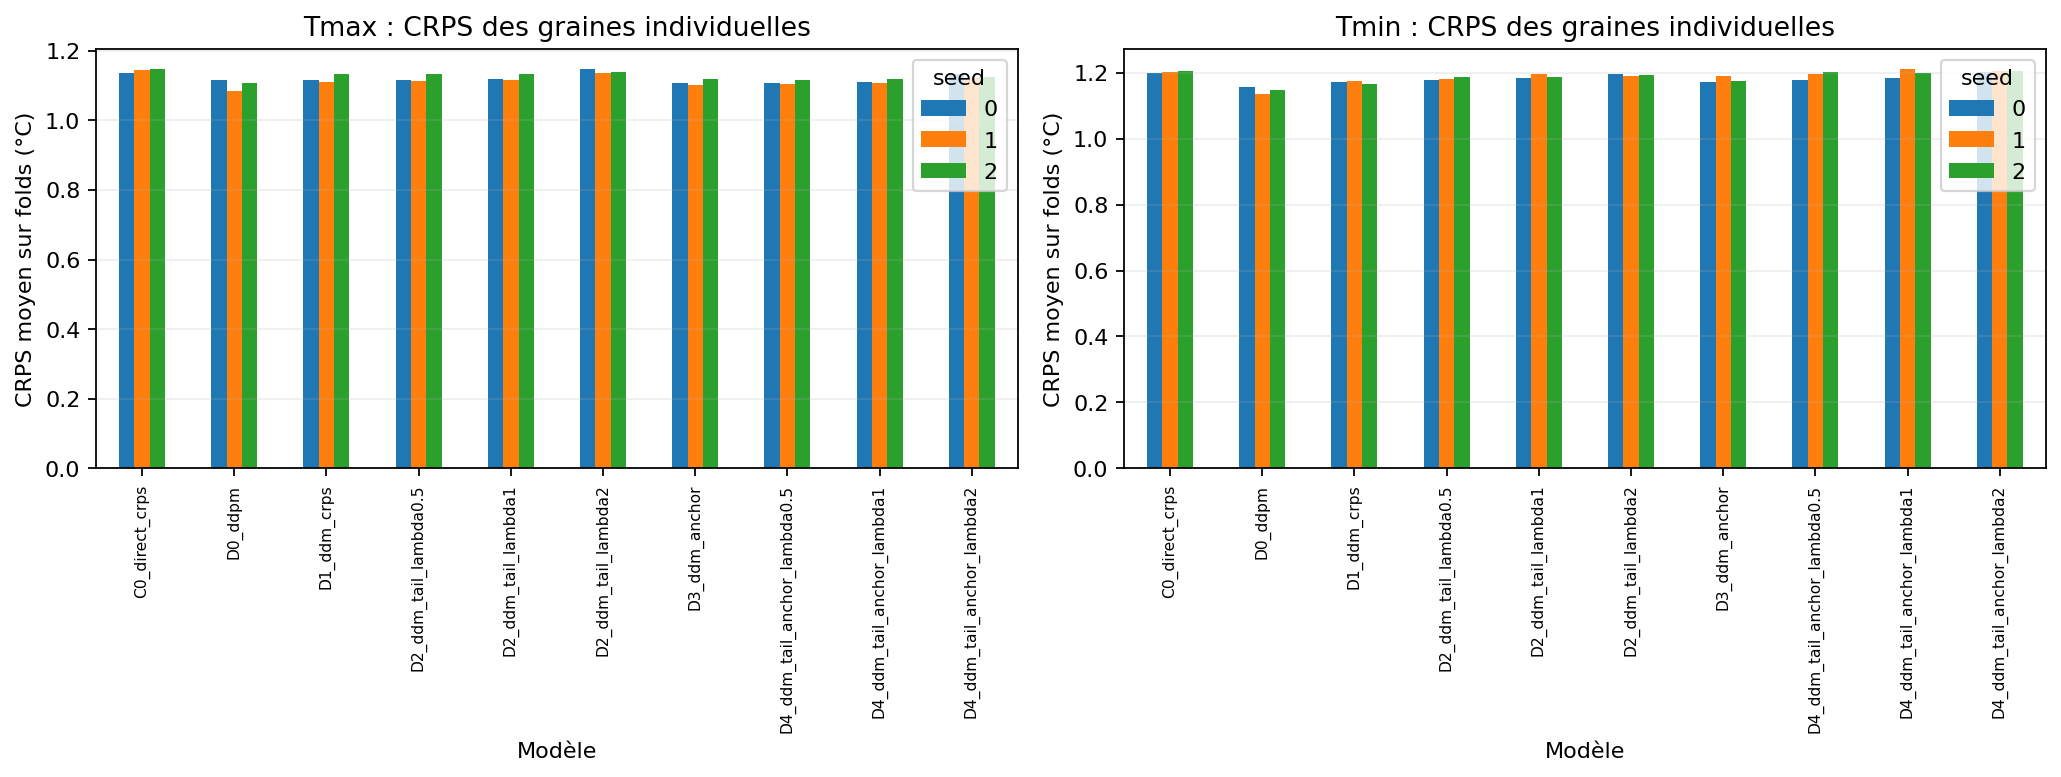

In [6]:
show_figures('competition', ['learning_curves_max', 'learning_curves_min', 'validation_ablation_max', 'validation_ablation_min', 'validation_seed_dispersion'])

## Choix enregistré avant lecture du test

Le critère principal est le CRPS moyen des trois folds. Avec un écart inférieur à 0,05 °C, la règle fixée de simplicité et coût s'applique. Le benchmark ne conduit pas à régler à nouveau ces choix.

In [7]:
selection = show_json(COMP / 'selection.json')
prechecks = show_json(COMP / 'prechecks.json')

```json
{
  "selected_models": {
    "max": "C0_direct_crps",
    "min": "D1_ddm_crps"
  },
  "selected_tail_lambda": {
    "max": 0.5,
    "min": 0.5
  },
  "final_steps": {
    "max": {
      "C0_direct_crps": 2750,
      "D0_ddpm": 2750,
      "D1_ddm_crps": 1250,
      "D2_ddm_tail_lambda0.5": 750,
      "D2_ddm_tail_lambda1": 750,
      "D2_ddm_tail_lambda2": 750
    },
    "min": {
      "C0_direct_crps": 2500,
      "D0_ddpm": 1250,
      "D1_ddm_crps": 1500,
      "D2_ddm_tail_lambda0.5": 1250,
      "D2_ddm_tail_lambda1": 1000,
      "D2_ddm_tail_lambda2": 1000
    }
  }
}
```

JSON complet : `artifacts\competition\selection.json`.

```json
{
  "R0_exact": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 4.965404634729429,
        "future_width80": 4.942500995700261,
        "projection_medians": [
          25.470792481078306,
          25.777845891176852,
          26.498615153997946
        ],
        "smallest": 16.611369581736106,
        "largest": 34.61264080806974,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.090125710577505,
        "future_width80": 5.07364239212788,
        "projection_medians": [
          -0.9773479513474066,
          -0.9463977399031842,
          -0.987482885639658
        ],
        "smallest": -10.021376273712725,
        "largest": 7.758253319971276,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "R0_gaussian": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.001831199612546,
        "future_width80": 5.001831199612546,
        "projection_medians": [
          25.42720841489747,
          25.759442718505667,
          26.464732832331464
        ],
        "smallest": 18.168590468583847,
        "largest": 33.68358718686018,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.048656571009092,
        "future_width80": 5.048656571009092,
        "projection_medians": [
          -0.9426152603212812,
          -0.9426152603212812,
          -0.9426152603212812
        ],
        "smallest": -8.215169038978454,
        "largest": 8.2337916348475,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "R1_gev": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 4.787537658196119,
        "future_width80": 4.787537658196118,
        "projection_medians": [
          25.290168458177583,
          25.622402761785786,
          26.327692875611575
        ],
        "smallest": 20.713375756678584,
        "largest": 35.15518529787518,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 4.865883530040231,
        "future_width80": 4.865883530040231,
        "projection_medians": [
          -0.6543606367191156,
          -0.6543606367191156,
          -0.6543606367191156
        ],
        "smallest": -12.890551474668774,
        "largest": 3.4887111089626788,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "R2_empirical": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.23863225056342,
        "future_width80": 5.23863225056342,
        "projection_medians": [
          25.097643159481454,
          25.429877463089653,
          26.135167576915446
        ],
        "smallest": 21.879520966980213,
        "largest": 31.49937347241447,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.24169921875,
        "future_width80": 5.24169921875,
        "projection_medians": [
          -0.726531982421875,
          -0.726531982421875,
          -0.726531982421875
        ],
        "smallest": -6.604339599609375,
        "largest": 2.195220947265625,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "D0_ddpm": {
    "admissible": false,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 4.922453786273252,
        "future_width80": 4.922453786273252,
        "projection_medians": [
          25.150073670118797,
          25.482307973726996,
          26.18759808755279
        ],
        "smallest": 20.476337700839085,
        "largest": 33.38101653164206,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": false,
        "test_width80": 6.900453860087538,
        "future_width80": 6.900453860087538,
        "projection_medians": [
          -0.9324214096577538,
          -0.9324214096577538,
          -0.9324214096577538
        ],
        "smallest": -1933.2162934916798,
        "largest": 3.8422453567697725,
        "outside_bounds": 19152,
        "non_degenerate": true
      }
    },
    "errors": [
      "min: bornes"
    ]
  },
  "C0_direct_crps": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.019624766399222,
        "future_width80": 5.019624766399222,
        "projection_medians": [
          25.12611635511299,
          25.458350658721187,
          26.163640772546984
        ],
        "smallest": 18.576956242120726,
        "largest": 36.66408503779437,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 4.829217018255687,
        "future_width80": 4.829217018255687,
        "projection_medians": [
          -0.5777938358079773,
          -0.5777938358079773,
          -0.5777938358079773
        ],
        "smallest": -14.330419058181885,
        "largest": 4.188416737276608,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "D1_ddm_crps": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.9967564830527955,
        "future_width80": 5.9967564830527955,
        "projection_medians": [
          25.260616131144772,
          25.59285043475297,
          26.298140548578765
        ],
        "smallest": 18.730902294056346,
        "largest": 37.36128962446605,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.679084563718272,
        "future_width80": 5.679084563718271,
        "projection_medians": [
          -0.7219305511629748,
          -0.7219305511629748,
          -0.7219305511629748
        ],
        "smallest": -10.900842489801107,
        "largest": 4.743346329913901,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "D2_ddm_tail": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.914733674209865,
        "future_width80": 5.914733674209863,
        "projection_medians": [
          25.264910869663034,
          25.597145173271237,
          26.302435287097026
        ],
        "smallest": 18.249296329576556,
        "largest": 37.08266671277073,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.780186414070175,
        "future_width80": 5.780186414070174,
        "projection_medians": [
          -0.6233150954706991,
          -0.6233150954706991,
          -0.6233150954706991
        ],
        "smallest": -11.426074457346932,
        "largest": 5.149104951746924,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "D3_ddm_anchor": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 6.057153827308047,
        "future_width80": 8.901339380691912,
        "projection_medians": [
          25.406626396750383,
          25.964905486576725,
          26.959169445006612
        ],
        "smallest": 18.25836183153258,
        "largest": 43.99741123322101,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.796358867130159,
        "future_width80": 8.058118042647415,
        "projection_medians": [
          -0.477885491658528,
          -0.11485767501694889,
          0.4848739047121464
        ],
        "smallest": -11.167645668431998,
        "largest": 16.42828281457346,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "D4_ddm_tail_anchor": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.987686766203007,
        "future_width80": 8.855857633334676,
        "projection_medians": [
          25.391674770453307,
          25.957941934362474,
          26.931521289987465
        ],
        "smallest": 17.77675586705279,
        "largest": 43.60594259798562,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.879688036579954,
        "future_width80": 8.13262397851614,
        "projection_medians": [
          -0.3902940300418625,
          -0.006111831432901171,
          0.575825044963186
        ],
        "smallest": -11.692877635977823,
        "largest": 16.445384685744827,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  },
  "participant": {
    "admissible": true,
    "variables": {
      "max": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.019624766399222,
        "future_width80": 5.019624766399222,
        "projection_medians": [
          25.12611635511299,
          25.458350658721187,
          26.163640772546984
        ],
        "smallest": 18.576956242120726,
        "largest": 36.66408503779437,
        "outside_bounds": 0,
        "non_degenerate": true
      },
      "min": {
        "monotonic": true,
        "width_ok": true,
        "bounds_ok": true,
        "test_width80": 5.679084563718272,
        "future_width80": 5.679084563718271,
        "projection_medians": [
          -0.7219305511629748,
          -0.7219305511629748,
          -0.7219305511629748
        ],
        "smallest": -10.900842489801107,
        "largest": 4.743346329913901,
        "outside_bounds": 0,
        "non_degenerate": true
      }
    },
    "errors": []
  }
}
```

JSON complet : `artifacts\competition\prechecks.json`.

## Benchmark original : résultats et échecs

Les NPZ bruts sont conservés. Un modèle avec un bon CRPS qui échoue aux contrôles reste éliminé ; la valeur de retour du kit et ses sorties sont consignées. La reproduction de l'exemple R0 conserve ses appels RNG dans l'ordre exact.

In [8]:
benchmark = show_csv(COMP / 'benchmark_scores.csv')
benchmark_record = show_json(COMP / 'benchmark_results.json')
show_ddpm_failure()

,model,crps_max,crps_min,admissible,errors
0,R0_exact,1.698885,1.064129,True,—
1,R0_gaussian,1.707689,1.064495,True,—
2,R1_gev,1.727800,1.036027,True,—
3,R2_empirical,1.735000,1.030154,True,—
4,D0_ddpm,1.750060,2.619998,False,min: bornes
5,C0_direct_crps,1.748986,1.027042,True,—
6,D1_ddm_crps,1.700707,1.031040,True,—
7,D2_ddm_tail,1.706913,1.014643,True,—
8,D3_ddm_anchor,1.649194,0.987842,True,—
9,D4_ddm_tail_anchor,1.654758,0.978821,True,—


CSV complet : `artifacts\competition\benchmark_scores.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

```json
{
  "candidate": "participant",
  "admissible_count": 10,
  "results": [
    {
      "id": "R0_exact",
      "scores": {
        "max": 1.6988852701291457,
        "min": 1.0641289751743772
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "R0_gaussian",
      "scores": {
        "max": 1.707688996847894,
        "min": 1.0644949748928358
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "R1_gev",
      "scores": {
        "max": 1.7278003858940625,
        "min": 1.0360269163426836
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "R2_empirical",
      "scores": {
        "max": 1.7349998610169282,
        "min": 1.0301538323498536
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "D0_ddpm",
      "scores": {
        "max": 1.7500600178428527,
        "min": 2.6199984416607776
      },
      "admissible": false,
      "errors": [
        "min: bornes"
      ]
    },
    {
      "id": "C0_direct_crps",
      "scores": {
        "max": 1.7489856249632312,
        "min": 1.0270418442716416
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "D1_ddm_crps",
      "scores": {
        "max": 1.7007066243979159,
        "min": 1.0310398764272761
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "D2_ddm_tail",
      "scores": {
        "max": 1.706913238764483,
        "min": 1.0146430026324984
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "D3_ddm_anchor",
      "scores": {
        "max": 1.649194364649759,
        "min": 0.9878422521383422
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "D4_ddm_tail_anchor",
      "scores": {
        "max": 1.6547580378477371,
        "min": 0.9788205668031597
      },
      "admissible": true,
      "errors": []
    },
    {
      "id": "participant",
      "scores": {
        "max": 1.7489856249632312,
        "min": 1.0310398764272761
      },
      "admissible": true,
      "errors": []
    }
  ]
}
```

JSON complet : `artifacts\competition\benchmark_results.json`.

**DDPM D0 est éliminé** : 19152 valeurs de Tmin sortent de [−30,20] °C ; le minimum simulé atteint **-1933.216 °C**. Son CRPS Tmin brut est **2.619998 °C** et le kit retourne None. Un bon score de validation ne rend donc pas cette configuration admissible.

Les 684 tirages froids de la graine 2 (20.522 % de ses 3333 membres) sont réutilisés sur les 25 années de test et 3 scénarios : les 19 152 occurrences ne sont pas des anomalies climatiques indépendantes. Les graines 0 et 1 ne sortent pas des bornes. Pour la graine 2, médiane **-1.332 °C** et moyenne **-109.345 °C** révèlent une queue froide explosive. L'ancre Tmin a b=0 : l'extrapolation CO₂ n'est pas l'origine de cet échec. Le diagnostic des checkpoints décrit une amplification plausible des erreurs par la récursion DDPM et une sensibilité à la durée fixée. Il ne démontre pas qu'un entraînement plus long résoudrait le problème. Aucun entraînement, rejet, clipping ou changement de graine n'a été appliqué en réaction au test.

Détails : [diagnostic_echec_ddpm.md](<C:/Users/edlas/OneDrive/Documents/ChatGPT/Mini projet stochastique/reports/diagnostic_echec_ddpm.md>), fondé sur le NPZ et les checkpoints figés.

## Calibration, localisation et événements

La couverture et la largeur complètent le CRPS. Le PIT est un diagnostic descriptif avec 25 points par modèle ; le Brier inclut les non-événements.

,variable,model,crps,twcrps,coverage80,width80,bias,brier
0,max,R0_exact,1.698885,0.728511,0.64,4.965405,-1.394732,0.342052
1,min,R0_exact,1.064129,0.154530,0.76,5.090126,-0.855062,0.128053
2,max,R0_gaussian,1.707689,0.729612,0.64,5.001831,-1.423197,0.342997
3,min,R0_gaussian,1.064495,0.152300,0.76,5.048657,-0.841032,0.123463
4,max,R1_gev,1.727800,0.724281,0.64,4.787538,-1.389278,0.347571
5,min,R1_gev,1.036027,0.149818,0.72,4.865884,-0.877177,0.107309
6,max,R2_empirical,1.735000,0.696773,0.68,5.238632,-1.374147,0.316992
7,min,R2_empirical,1.030154,0.151386,0.76,5.241699,-0.848047,0.086166
8,max,D0_ddpm,1.750060,0.720418,0.64,4.922454,-1.451058,0.342035
9,min,D0_ddpm,2.619998,1.675810,0.76,6.900454,-37.139688,0.145746


CSV complet : `artifacts\competition\test_diagnostics.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

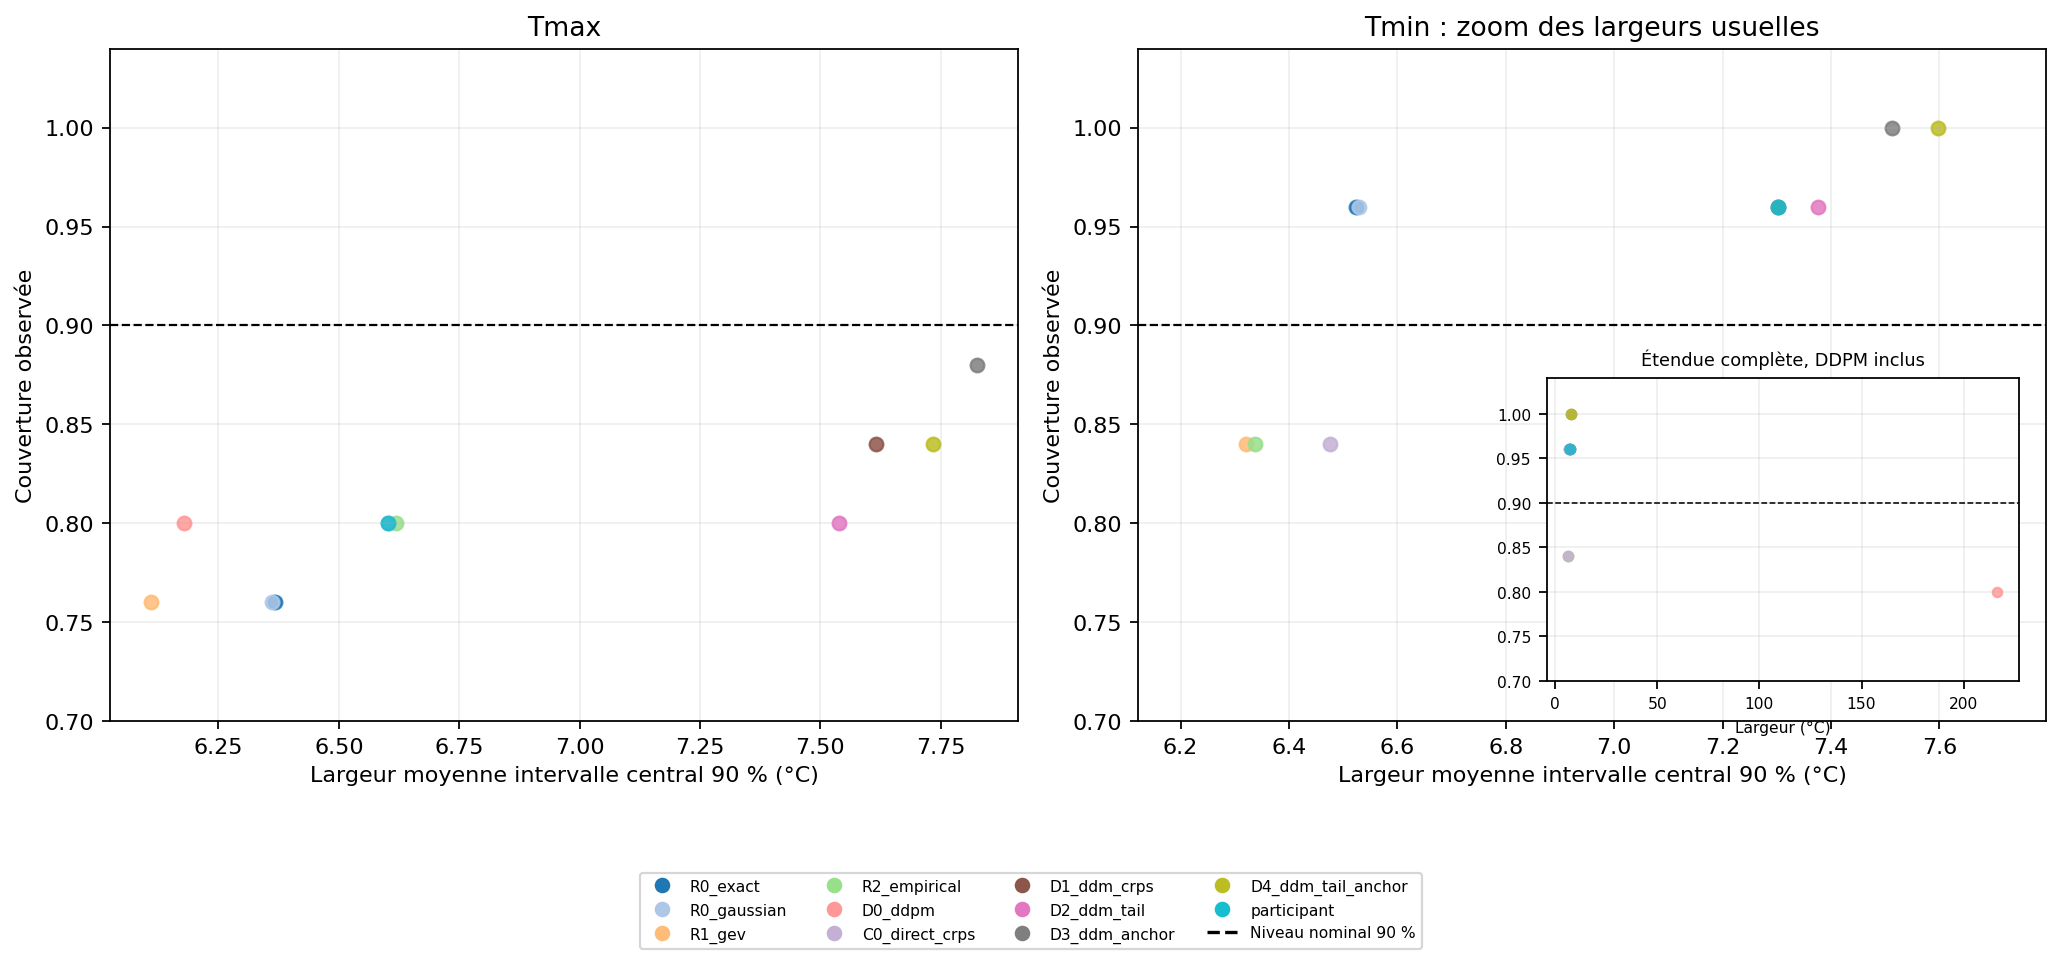

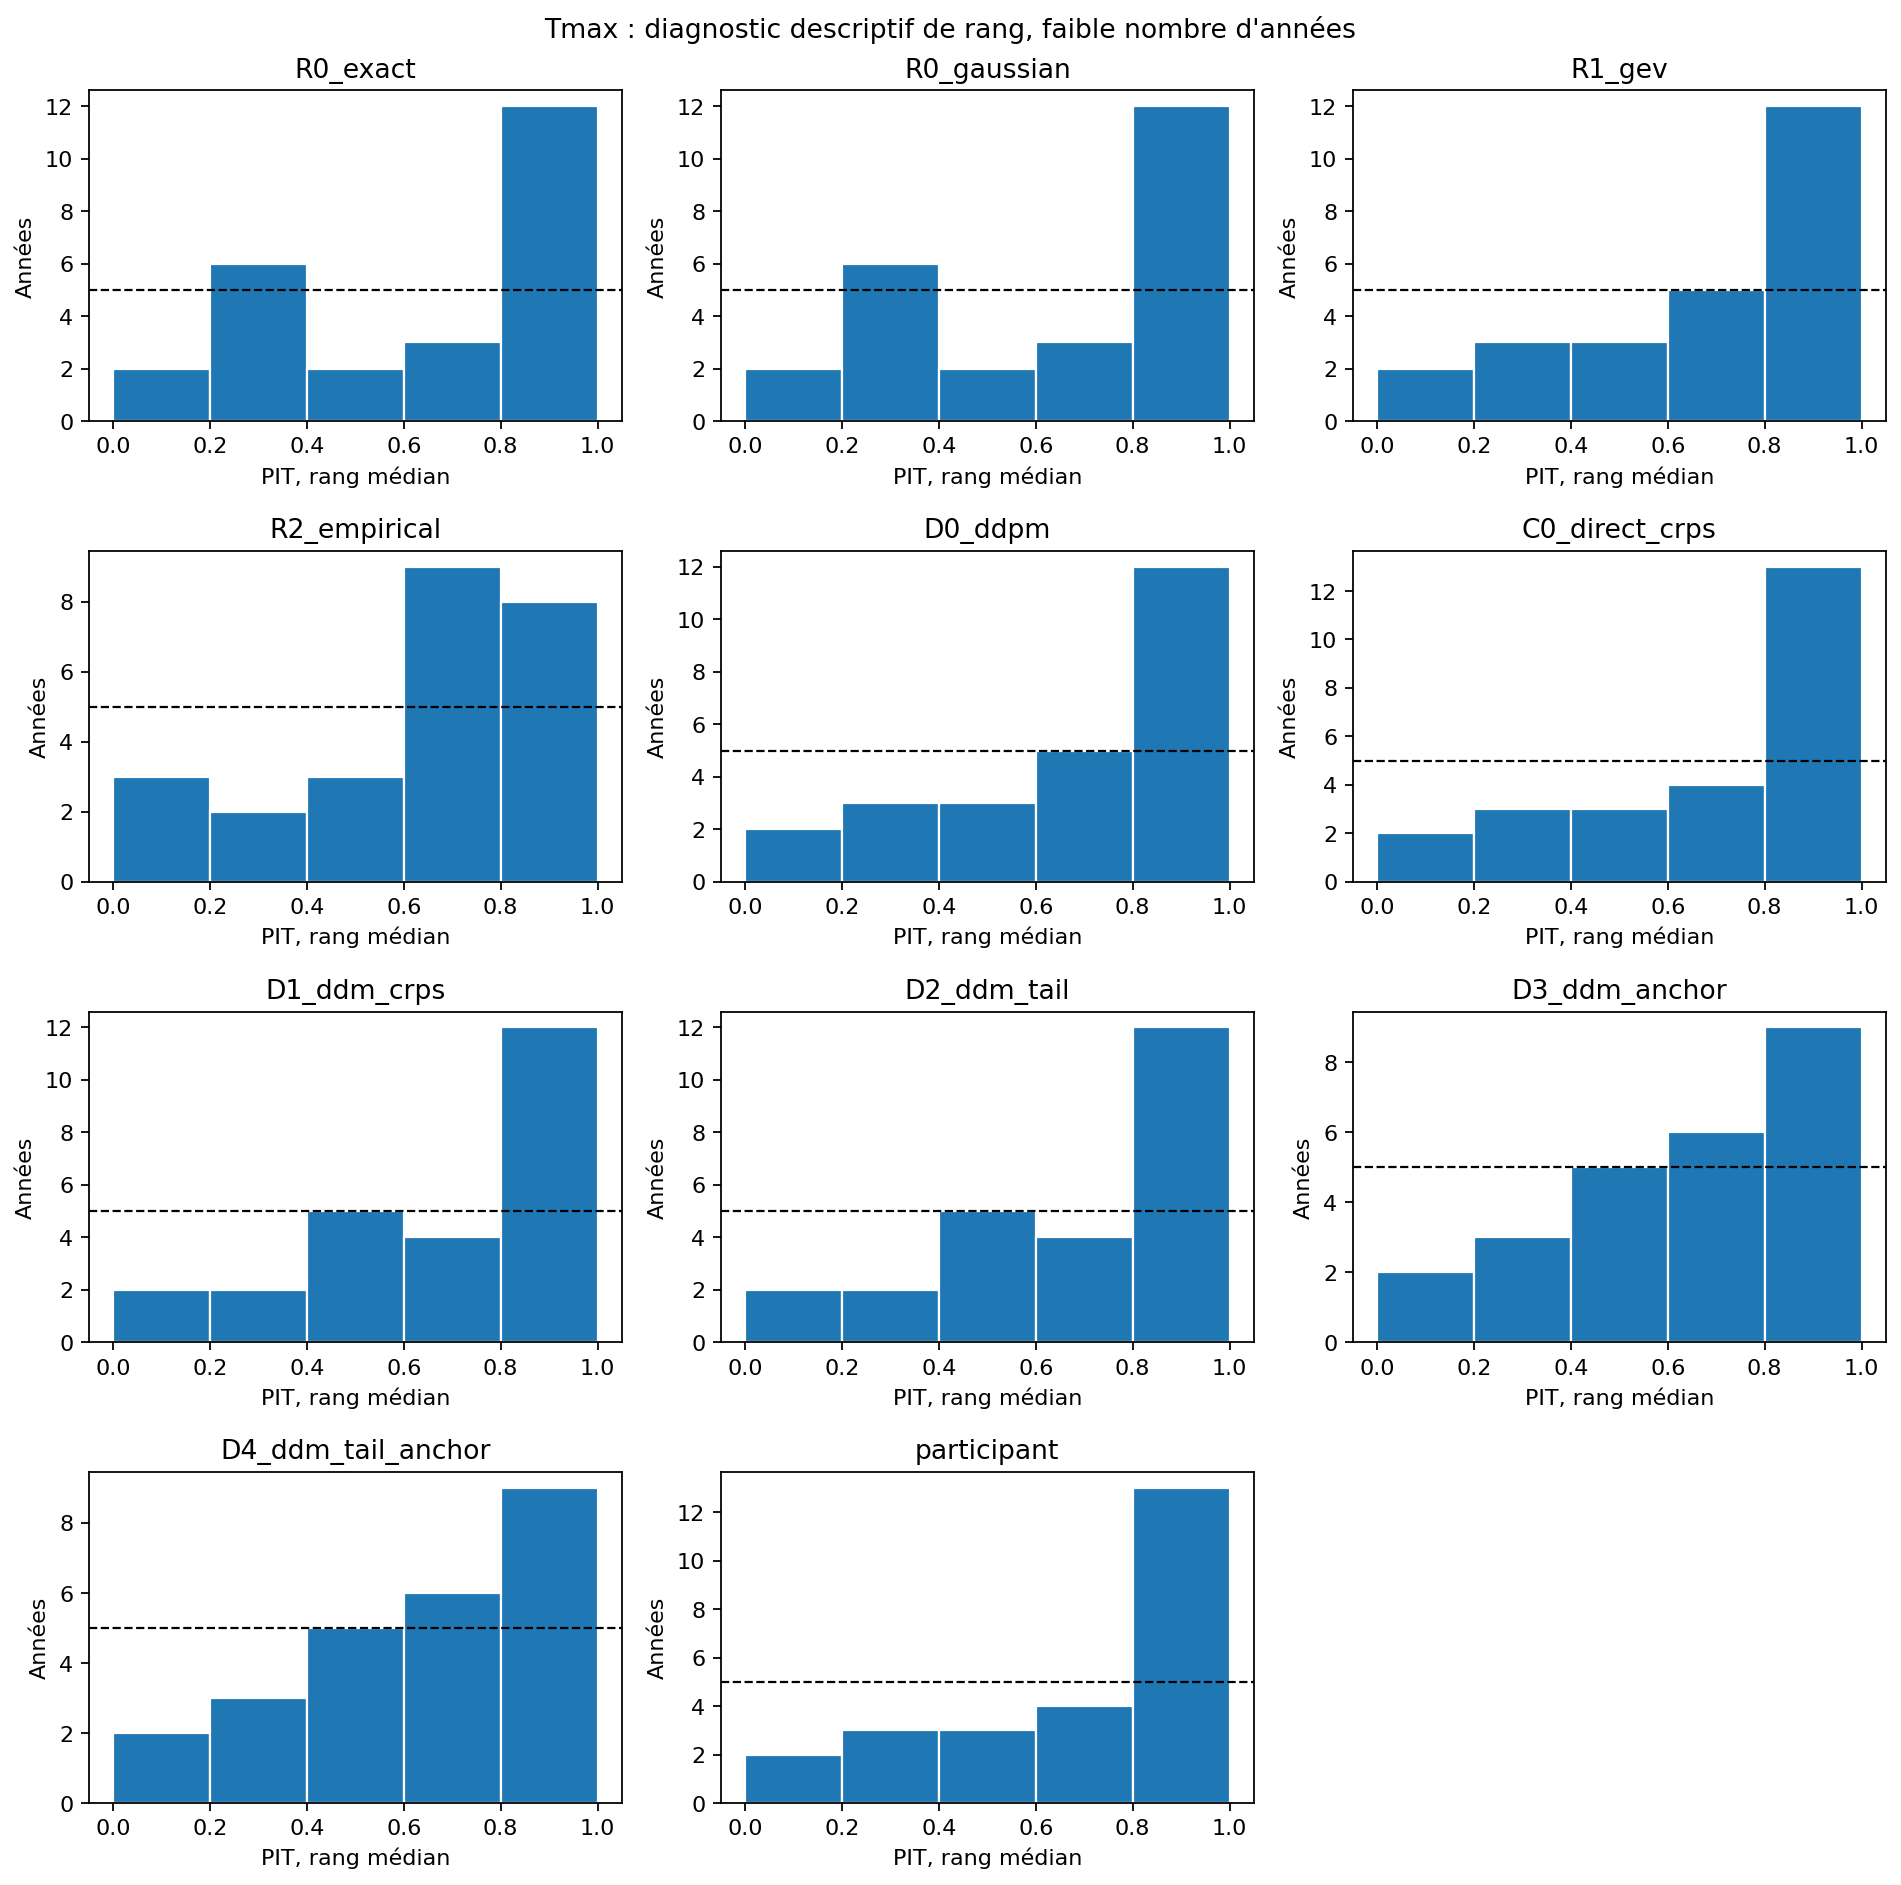

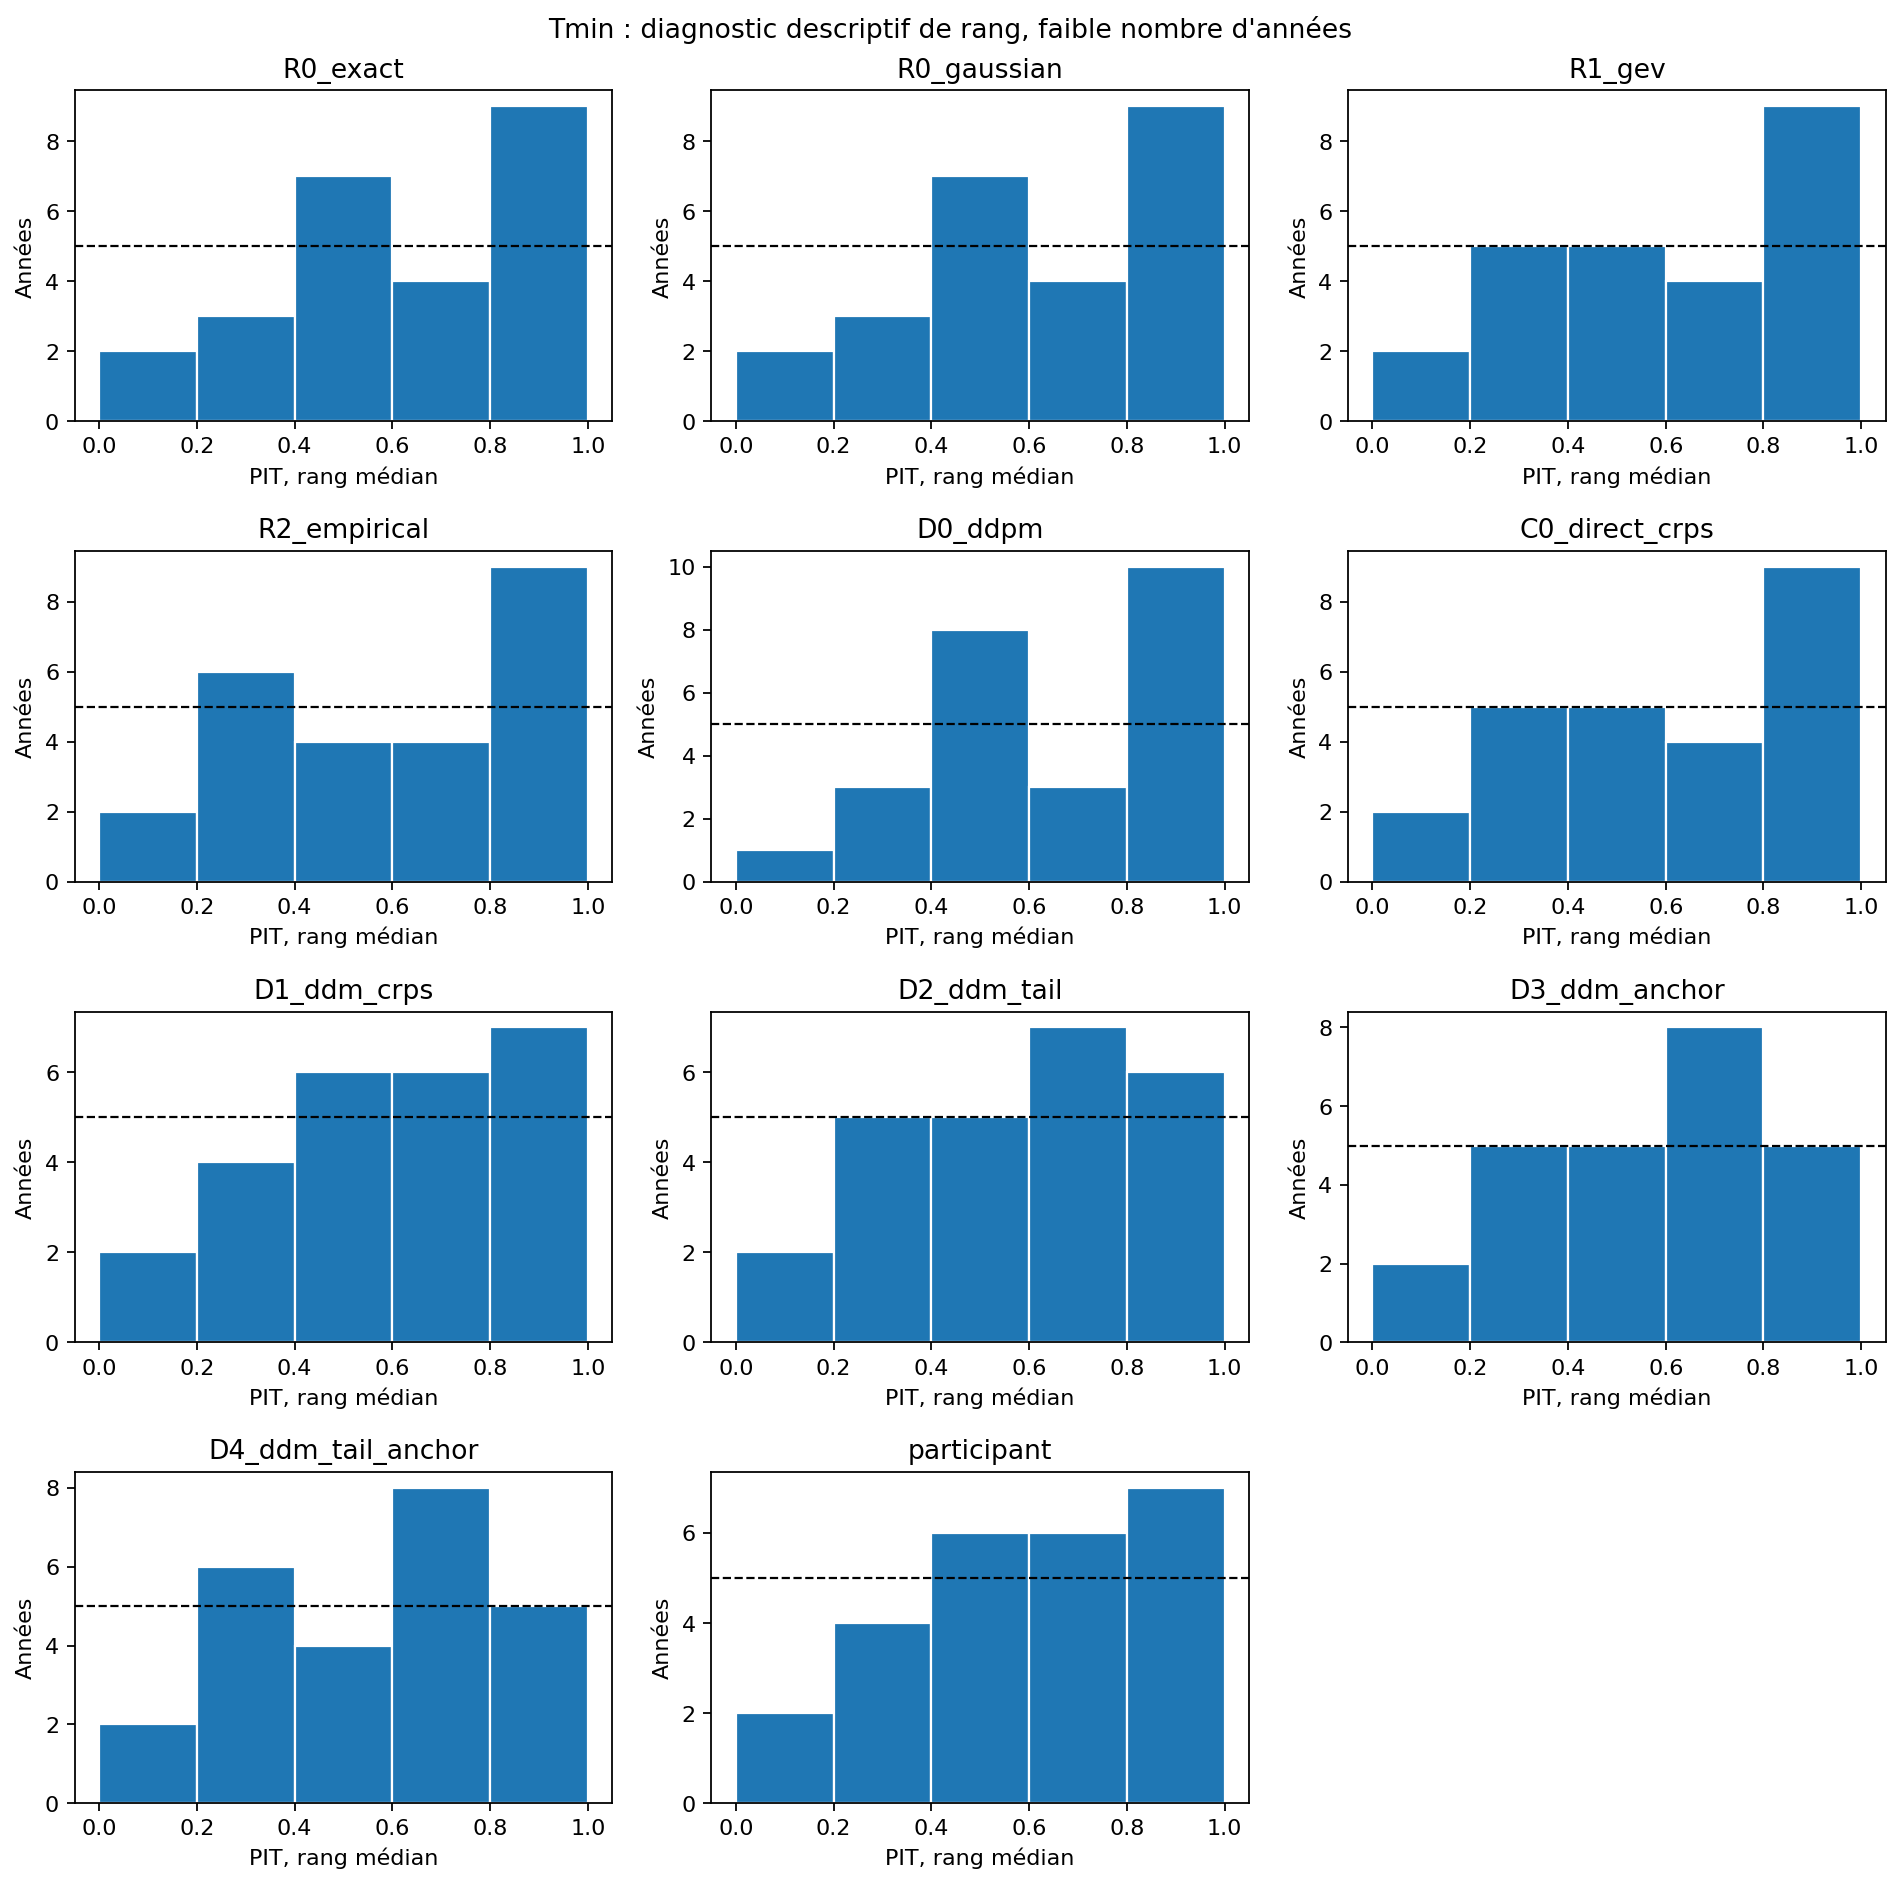

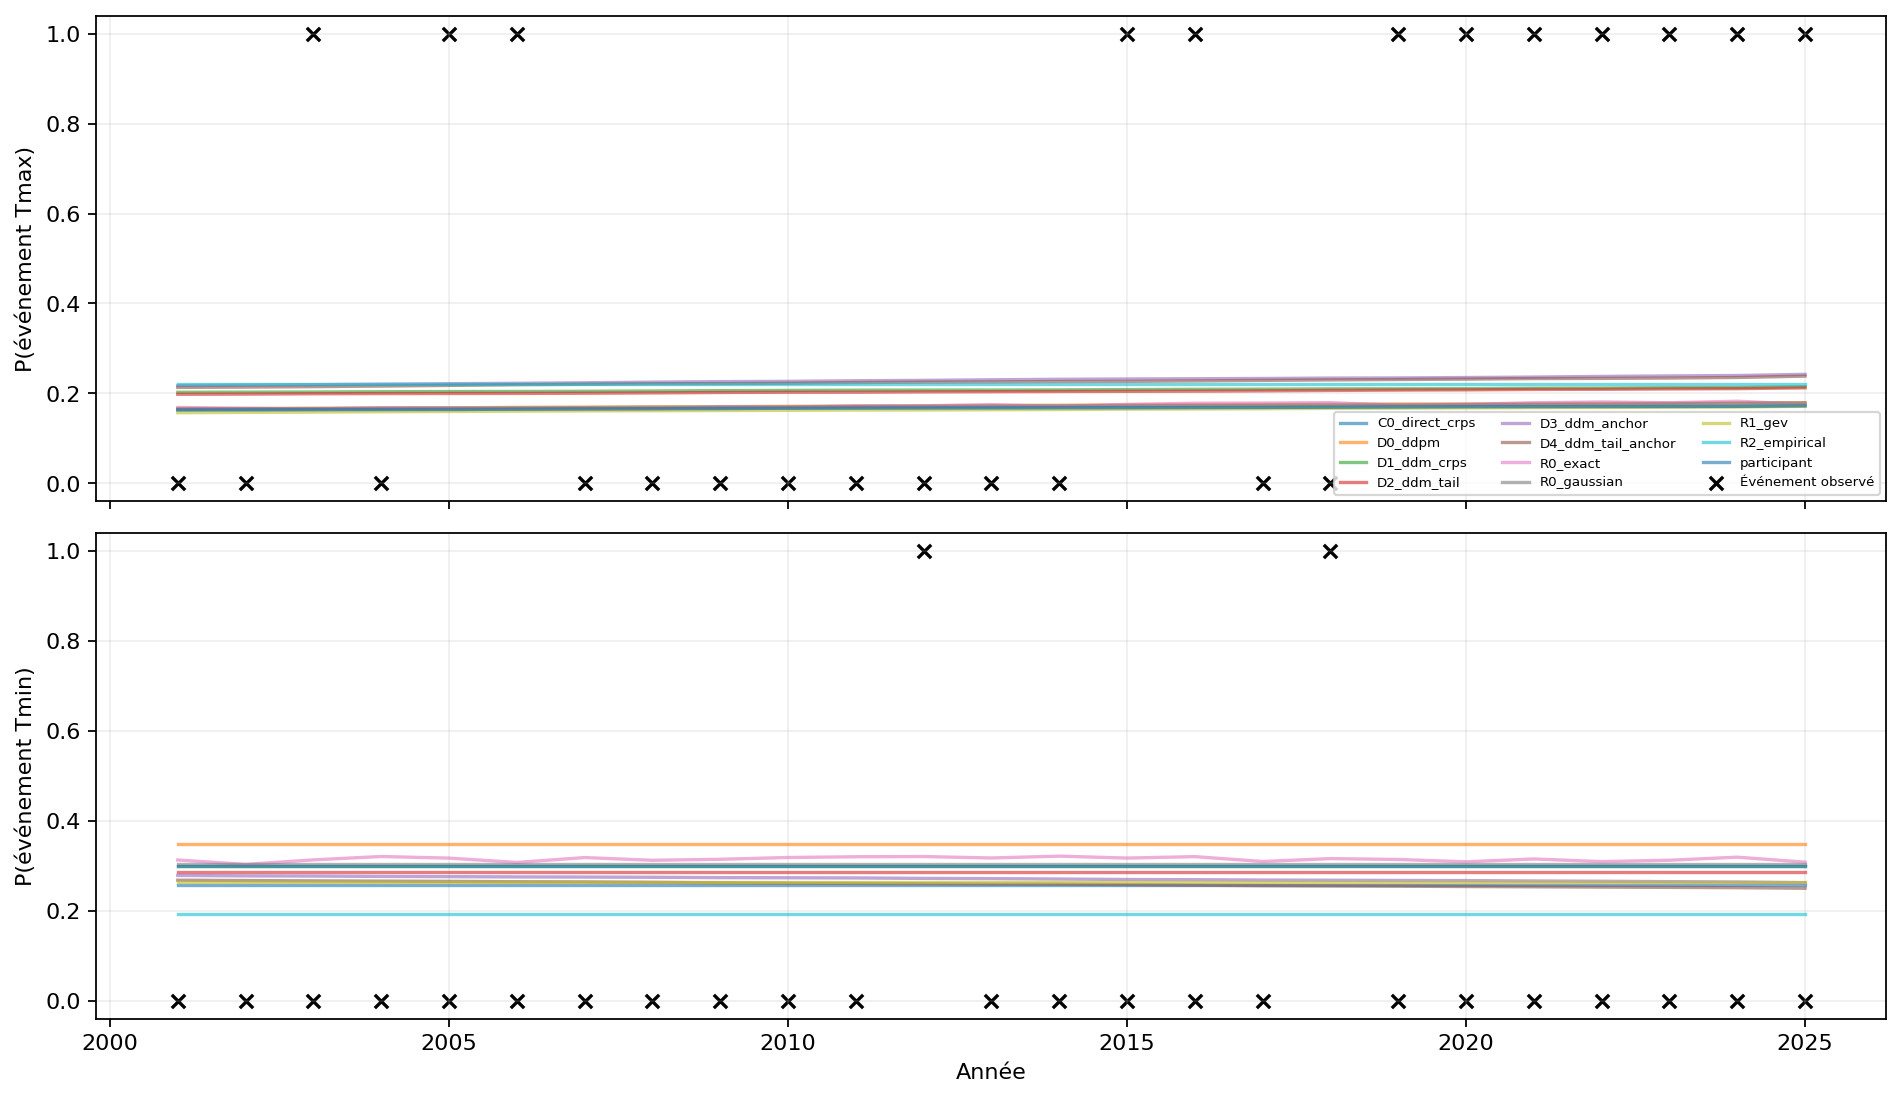

In [9]:
diagnostics = show_csv(COMP / 'test_diagnostics.csv')
show_figures('competition', ['coverage_width', 'pit_max', 'pit_min', 'event_probabilities'])

## Lois résiduelles et incertitude de l'ancre

Les tirages utilisés pour ces figures ont une graine de diagnostic séparée. Ils ne remplacent aucun NPZ officiel. L'ancre bootstrap varie ; l'échelle et les réseaux parents restent fixes.

**Diagnostics résiduels descriptifs : phase competition.**

,variable,n,skewness,autocorrelation_lag1,autocorrelation_lag2,autocorrelation_lag3,q05_C,q50_C,q95_C
0,max,61,0.539111,0.095766,-0.027872,-0.279528,-2.590840,-0.369943,3.290583
1,min,61,-0.844310,0.172911,0.047386,-0.312092,-3.644917,0.235088,2.693309


CSV complet : `artifacts\competition\annual_analysis\residual_descriptive.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

Tmax (61 années) : asymétrie descriptive **+0.539**, quantiles q05/q50/q95 **-2.591 / -0.370 / 3.291 °C**, autocorrélations aux retards 1/2/3 ans **+0.096 / -0.028 / -0.280**. L'asymétrie positive décrit une queue empirique plus étendue vers les résidus chauds.

Tmin (61 années) : asymétrie descriptive **-0.844**, quantiles q05/q50/q95 **-3.645 / 0.235 / 2.693 °C**, autocorrélations aux retards 1/2/3 ans **+0.173 / +0.047 / -0.312**. L'asymétrie négative décrit une queue empirique plus étendue vers les résidus froids.

Ces valeurs concernent les résidus de l'ancre ajustée sur la période descriptive indiquée, et non des erreurs de validation calculées avec une ancre commune à tous les folds. Les autocorrélations décrivent une dépendance locale possible ; avec peu d'années, elles ne certifient ni indépendance, ni stationnarité, ni validité d'une queue GEV. Le bootstrap principal en blocs de trois ans conserve une partie de cette dépendance possible ; la comparaison avec des blocs d'un an est une sensibilité fixée avant le test.

,variable,model,mean_C,std_C,minimum_C,q50_C,maximum_C,fraction_outside_central_window
0,max,R0_gaussian,-0.005639,1.941251,-7.148640,-0.019998,7.124606,0.0103
1,max,R1_gev,0.011572,1.898768,-4.849634,-0.186661,8.446795,0.0046
2,max,R2_empirical,-0.025078,1.904415,-3.556048,-0.369943,4.994263,0.0000
3,max,D0_ddpm,-0.037571,1.874559,-5.125246,-0.281462,6.874378,0.0014
4,max,C0_direct_crps,0.018283,2.016317,-6.357100,-0.306338,11.201662,0.0125
5,max,D1_ddm_crps,-0.062090,2.318400,-6.863794,-0.202385,10.343533,0.0227
6,max,D2_ddm_tail,-0.035354,2.316428,-6.504780,-0.177472,12.663364,0.0222
7,min,R0_gaussian,-0.005775,1.988265,-7.321769,-0.020483,7.297153,0.0178
8,min,R1_gev,-0.017522,1.988939,-12.287683,0.307988,4.214756,0.0083
9,min,R2_empirical,0.019455,1.941908,-5.642720,0.235088,3.156841,0.0000


CSV complet : `artifacts\competition\residual_law_diagnostics.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,variable,model,co2_ppm,anchor_std_C,generator_residual_std_C,anchor_variance_fraction,anchor_mean_shift_C
0,max,D3_ddm_anchor,388.056704,0.386424,2.318400,0.027030,0.100977
1,max,D3_ddm_anchor,1000.000000,2.755726,2.318400,0.585552,0.957567
2,max,D3_ddm_anchor,400.000000,0.447744,2.318400,0.035957,0.128408
3,max,D3_ddm_anchor,526.987384,1.111096,2.318400,0.186782,0.377902
4,max,D3_ddm_anchor,946.222152,2.612877,2.318400,0.559504,0.907545
5,max,D4_ddm_tail_anchor,388.056704,0.386424,2.316428,0.027075,0.100977
6,max,D4_ddm_tail_anchor,1000.000000,2.755726,2.316428,0.585965,0.957567
7,max,D4_ddm_tail_anchor,400.000000,0.447744,2.316428,0.036016,0.128408
8,max,D4_ddm_tail_anchor,526.987384,1.111096,2.316428,0.187040,0.377902
9,max,D4_ddm_tail_anchor,946.222152,2.612877,2.316428,0.559923,0.907545


CSV complet : `artifacts\competition\bootstrap_dispersion.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

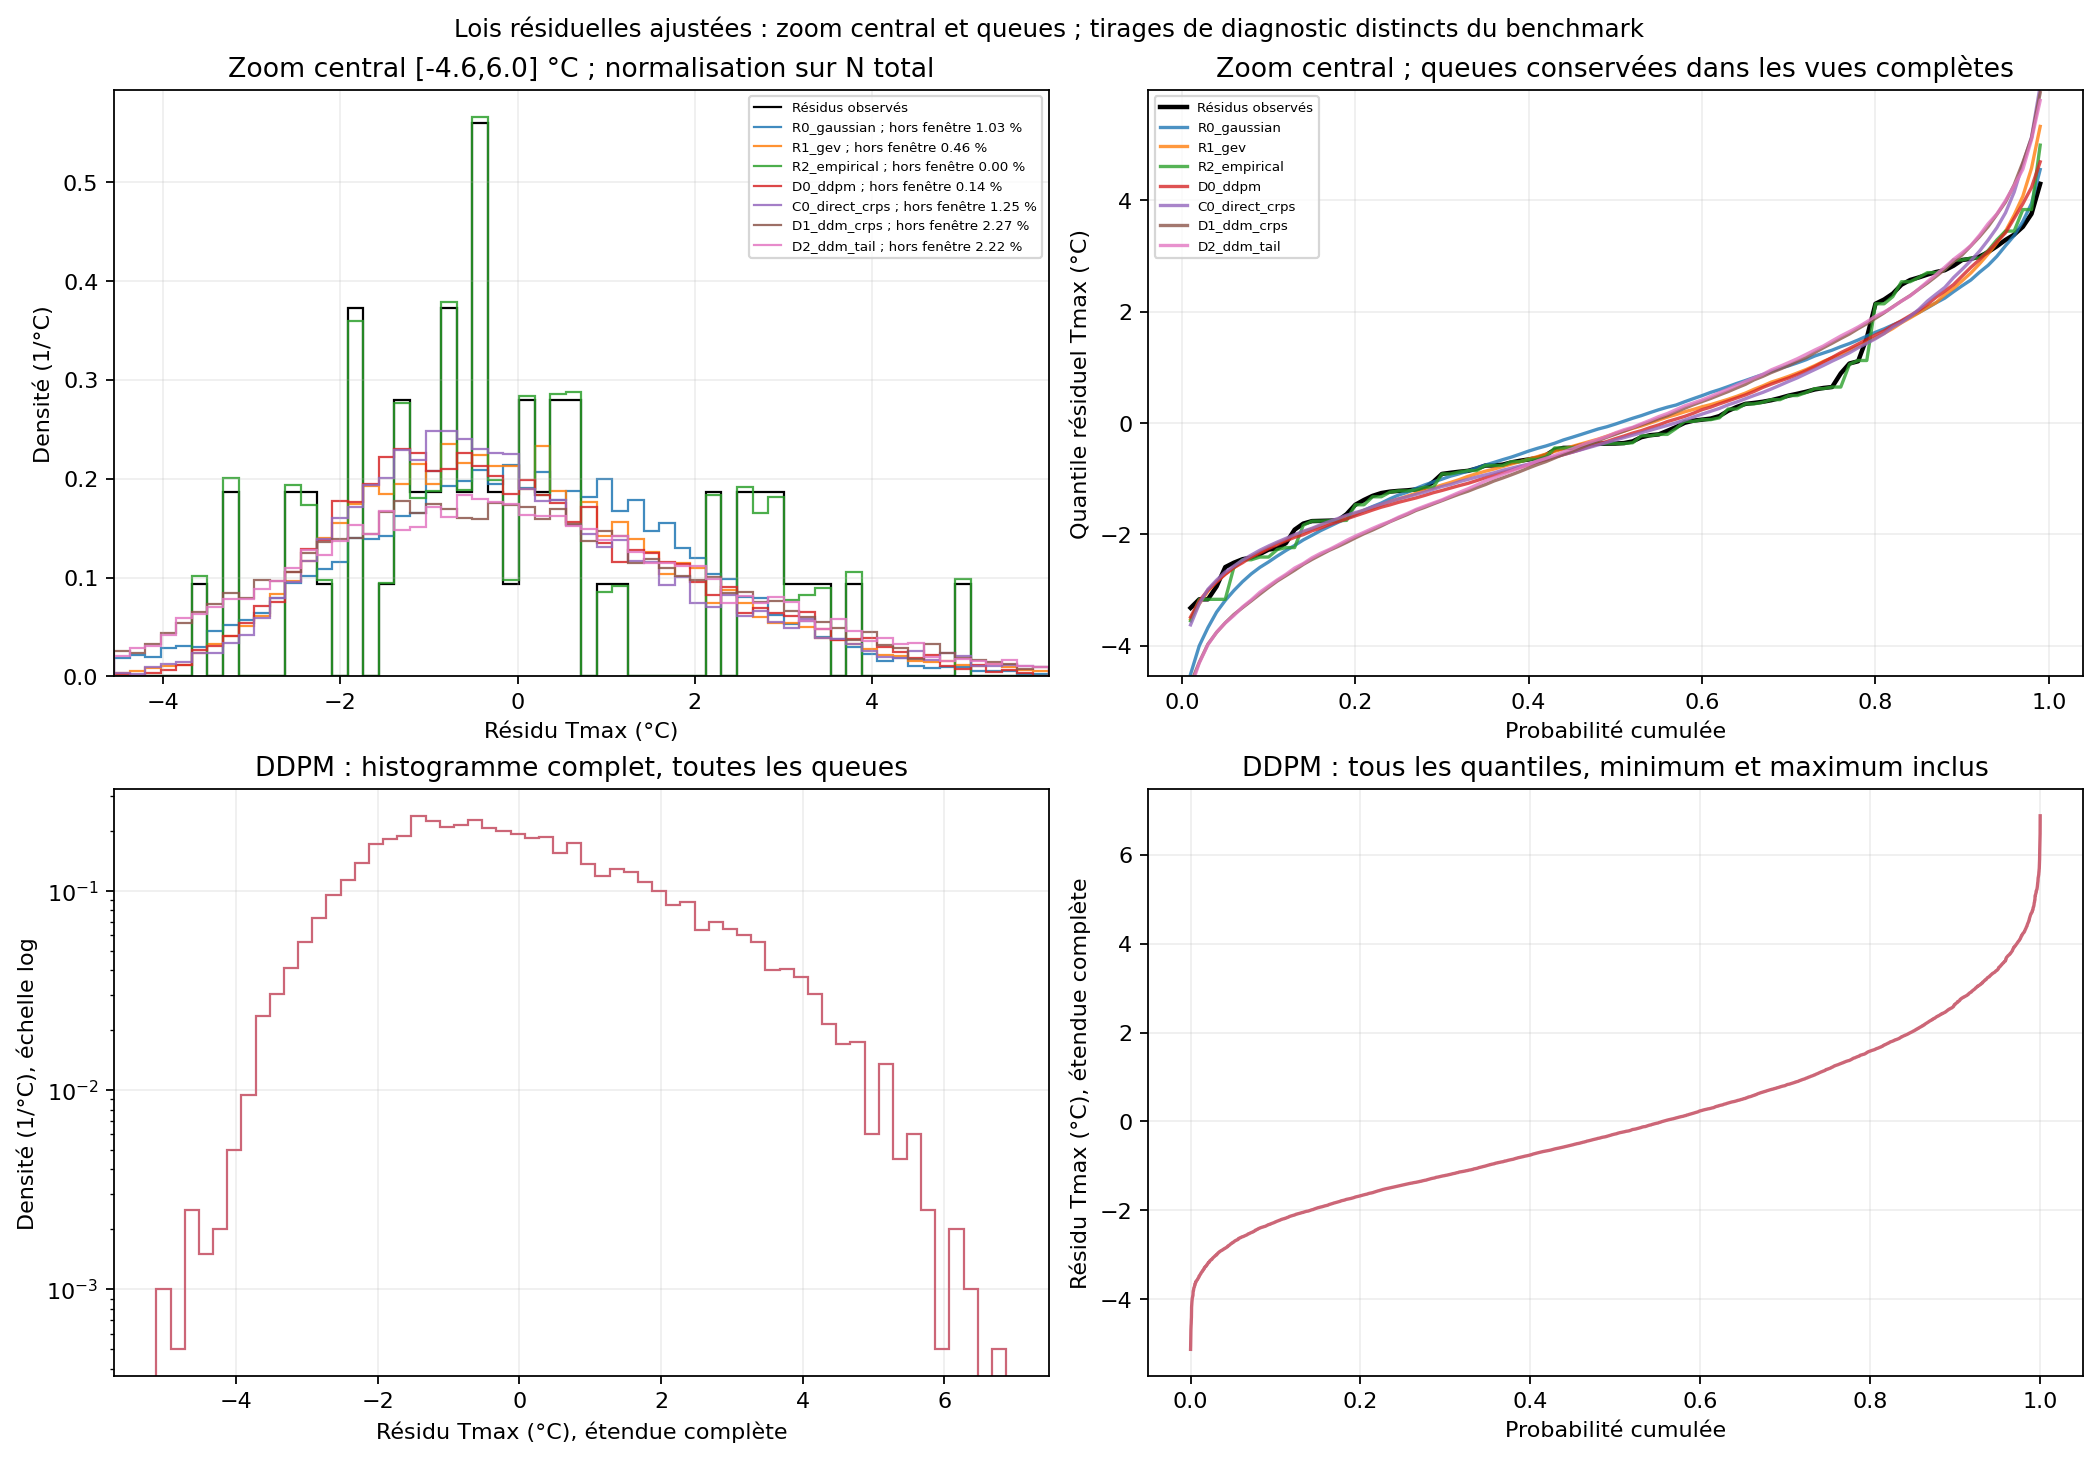

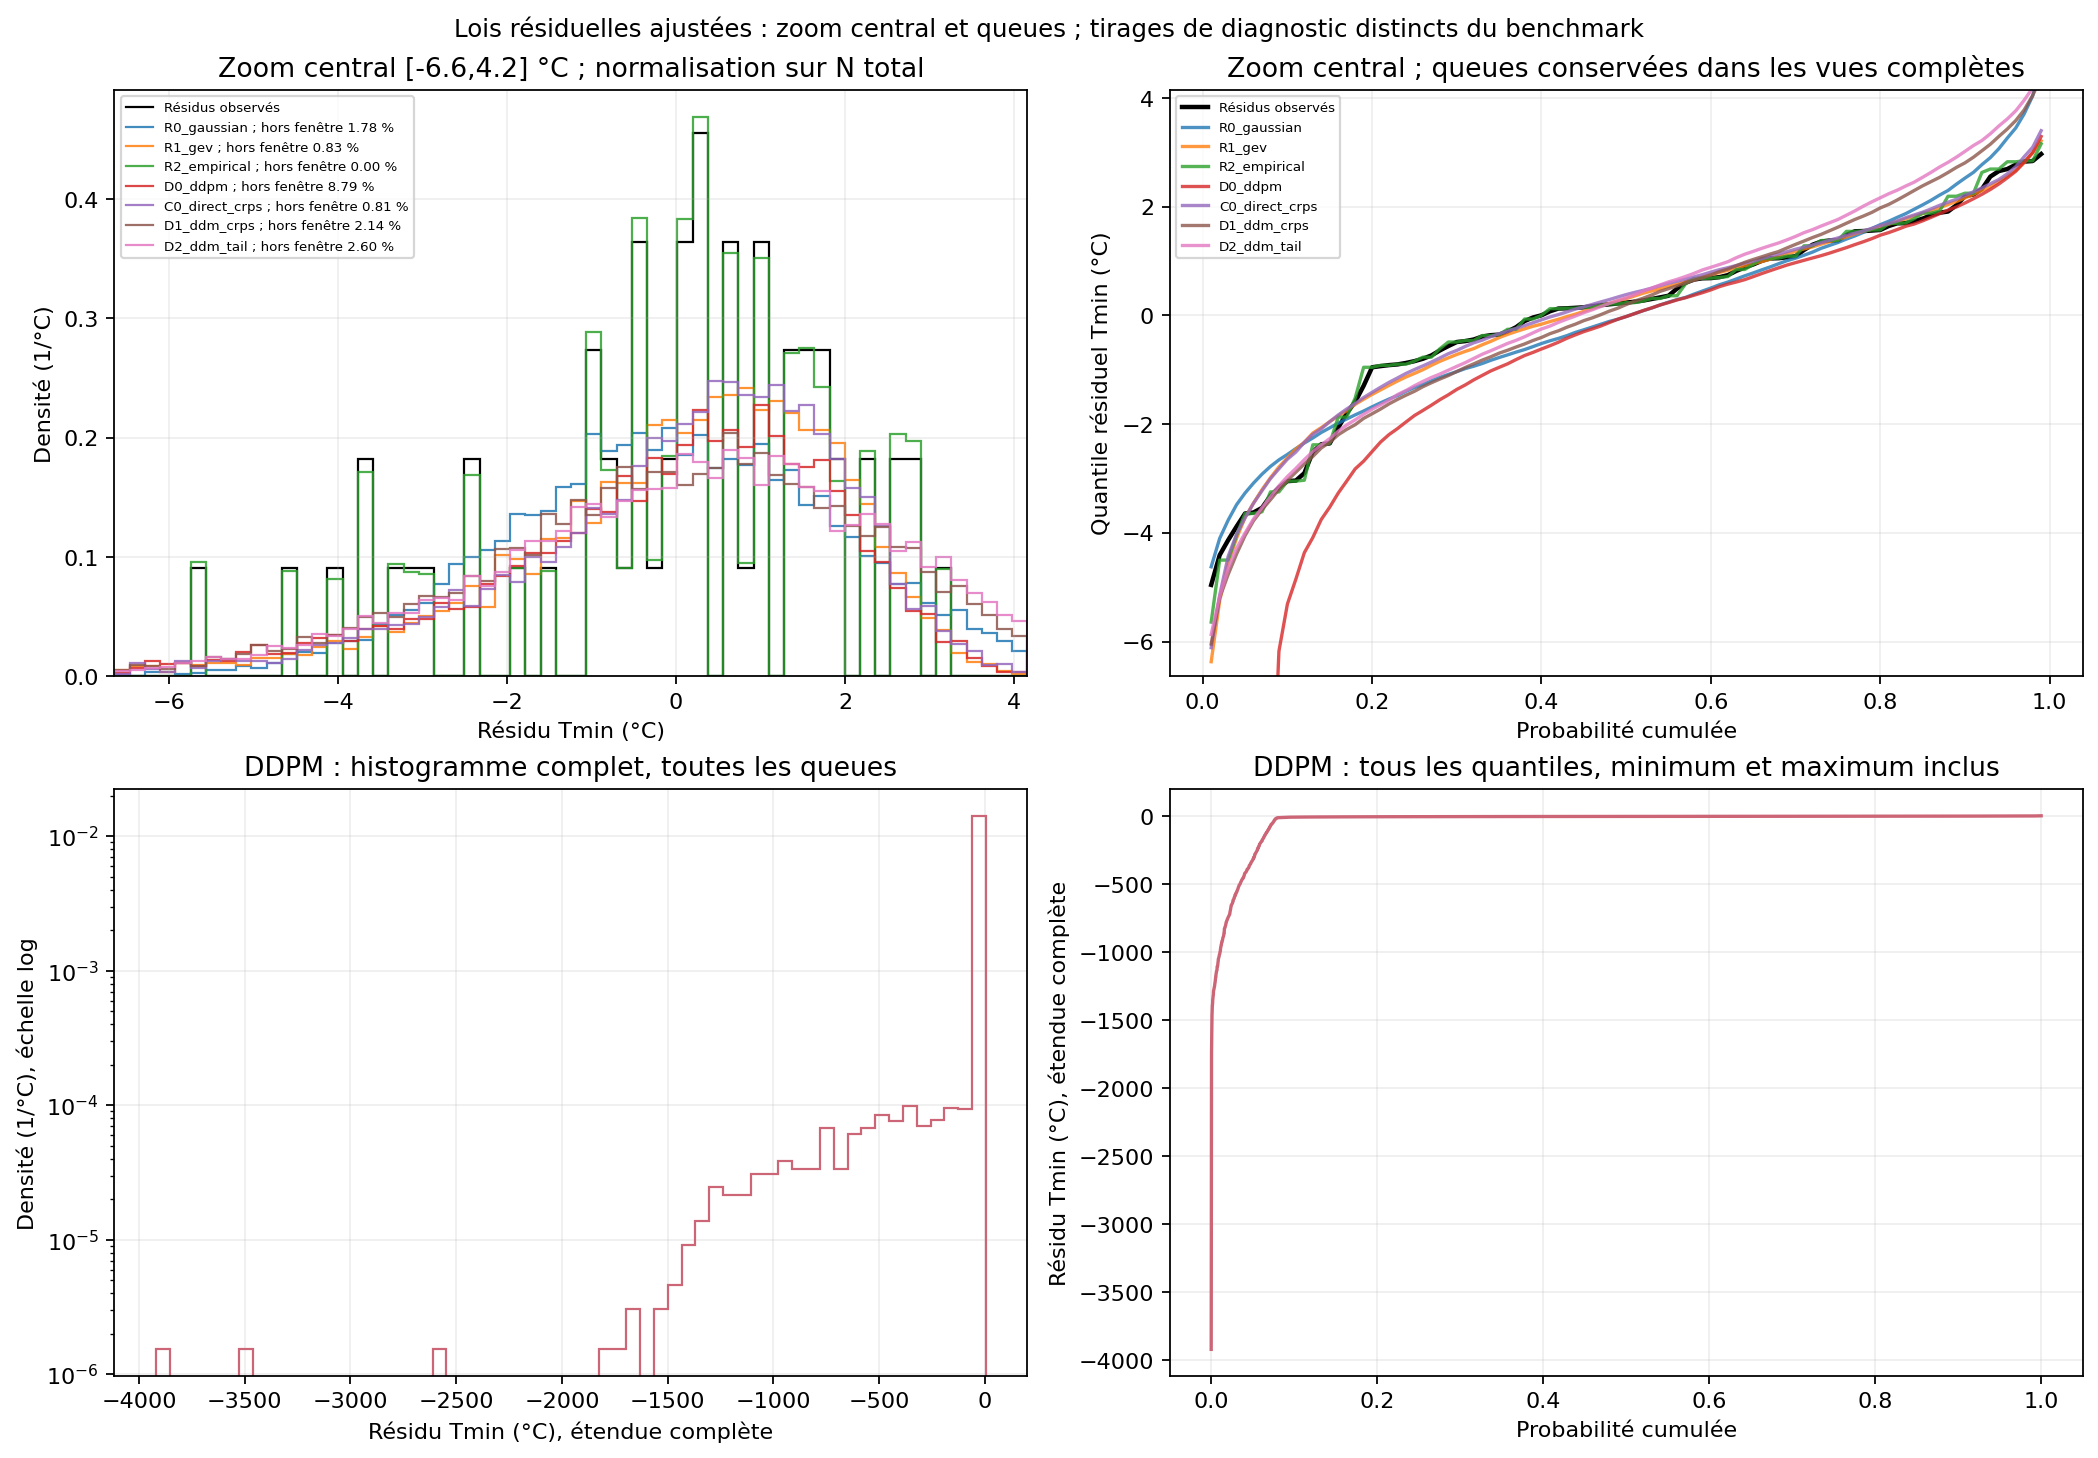

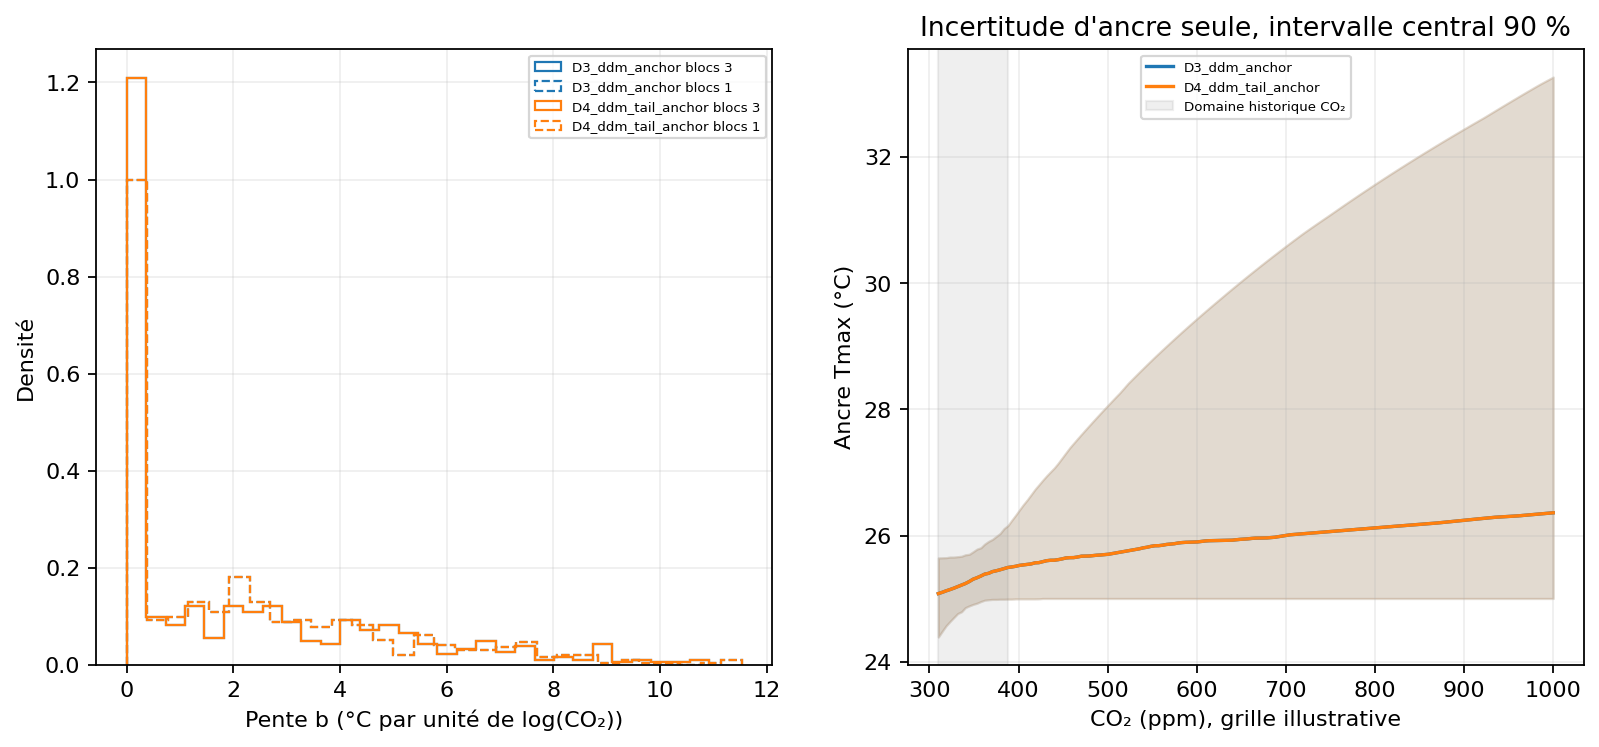

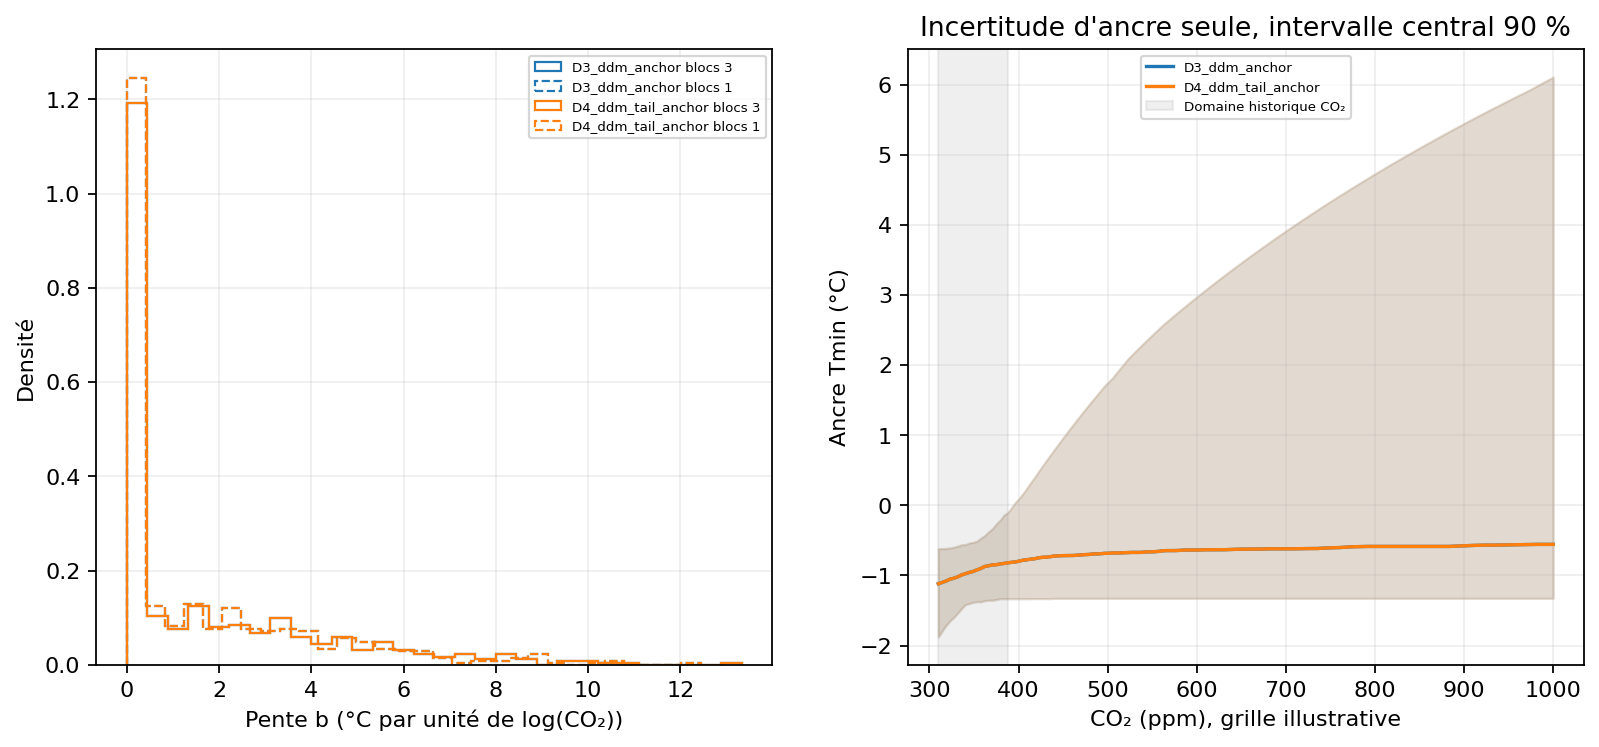

In [10]:
residuals_competition = show_residuals('competition')
laws = show_csv(COMP / 'residual_law_diagnostics.csv')
bootstrap = show_csv(COMP / 'bootstrap_dispersion.csv')
show_figures('competition', ['residual_laws_max', 'residual_laws_min', 'bootstrap_anchor_max', 'bootstrap_anchor_min'])

## Sensibilité fixée du bootstrap : blocs de 1 ou 3 ans

Les deux traitements conservent les mêmes réseaux résiduels, seuils, folds et années de validation. Les résultats restent séparés par modèle, λ et fold. Un delta blocs1 − blocs3 négatif favorise les blocs d'un an. Les blocs de trois ans restent le protocole principal ; cette sensibilité ne sélectionne rien sur le test. Les 500 ancres et 10 000 membres numériques n'augmentent pas le nombre d'années historiques.

In [11]:
block_sensitivity = show_csv(COMP / 'bootstrap_block_sensitivity_summary.csv')
block_folds = show_csv(COMP / 'bootstrap_block_sensitivity_by_fold.csv', 40)

,variable,model,tail_lambda,folds,delta_crps_block1_minus3_C,delta_twcrps_block1_minus3_C,folds_global_block1_better,folds_tail_block1_better
0,max,D3_ddm_anchor,0.0,3,0.004759,0.001693,1,1
1,max,D4_ddm_tail_anchor_lambda0.5,0.5,3,0.004668,0.001626,1,1
2,max,D4_ddm_tail_anchor_lambda1,1.0,3,0.004476,0.001627,1,1
3,max,D4_ddm_tail_anchor_lambda2,2.0,3,0.004625,0.001881,1,1
4,min,D3_ddm_anchor,0.0,3,-0.008110,0.000017,2,1
5,min,D4_ddm_tail_anchor_lambda0.5,0.5,3,-0.009798,-0.000127,2,1
6,min,D4_ddm_tail_anchor_lambda1,1.0,3,-0.009923,-0.000214,2,1
7,min,D4_ddm_tail_anchor_lambda2,2.0,3,-0.010071,0.000052,2,1


CSV complet : `artifacts\competition\bootstrap_block_sensitivity_summary.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,variable,model,fold,tail_lambda,delta_crps_block1_minus3_C,delta_twcrps_block1_minus3_C
0,max,D3_ddm_anchor,F1,0.0,-0.001653,-0.000041
1,max,D4_ddm_tail_anchor_lambda0.5,F1,0.5,-0.001735,-0.000120
2,max,D4_ddm_tail_anchor_lambda1,F1,1.0,-0.002456,-0.000130
3,max,D4_ddm_tail_anchor_lambda2,F1,2.0,-0.002608,-0.000216
4,max,D3_ddm_anchor,F2,0.0,0.006052,0.004108
5,max,D4_ddm_tail_anchor_lambda0.5,F2,0.5,0.005926,0.003973
6,max,D4_ddm_tail_anchor_lambda1,F2,1.0,0.006095,0.003973
7,max,D4_ddm_tail_anchor_lambda2,F2,2.0,0.007618,0.004638
8,max,D3_ddm_anchor,F3,0.0,0.009876,0.001012
9,max,D4_ddm_tail_anchor_lambda0.5,F3,0.5,0.009811,0.001026


CSV complet : `artifacts\competition\bootstrap_block_sensitivity_by_fold.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

## Temps et mémoire mesurés

Le temps de la boucle inclut ses évaluations : le temps d'inférence de validation est déjà inclus et ne doit pas lui être ajouté.

In [12]:
costs = show_csv(COMP / 'run_costs.csv', 50)

,variable,model_id,fold,seed,steps,best_step,training_seconds,gpu_memory_allocated_peak_bytes
0,max,C0_direct_crps,final,0,2750,2750,22.622758,19298304
1,max,C0_direct_crps,final,1,2750,2750,23.884361,19298304
2,max,C0_direct_crps,final,2,2750,2750,24.876391,19298304
3,max,D0_ddpm,final,0,2750,2750,22.338695,19268608
4,max,D0_ddpm,final,1,2750,2750,18.999097,19268608
5,max,D0_ddpm,final,2,2750,2750,24.733294,19268608
6,max,D1_ddm_crps,final,0,1250,1250,9.785936,19298304
7,max,D1_ddm_crps,final,1,1250,1250,10.367072,19298304
8,max,D1_ddm_crps,final,2,1250,1250,10.780917,19298304
9,max,D2_ddm_tail,final,0,750,750,8.959434,19298816


CSV complet : `artifacts\competition\run_costs.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

132 lignes conservées dans le CSV complet.

## Phase finale et probabilités extrêmes

Les modèles réentraînés sur 1940–2025 n'ont pas un score hors échantillon sur 2001–2025. Les intervalles Monte-Carlo sont conditionnels au modèle ; ils ne mesurent pas l'erreur de validité de la queue.

**Diagnostics résiduels descriptifs : phase full_project.**

,variable,n,skewness,autocorrelation_lag1,autocorrelation_lag2,autocorrelation_lag3,q05_C,q50_C,q95_C
0,max,86,0.585127,0.152690,0.115651,0.000496,-3.059216,-0.443665,3.501996
1,min,86,-0.817345,0.093573,-0.012267,-0.173522,-3.638232,0.190370,2.652572


CSV complet : `artifacts\full_project\annual_analysis\residual_descriptive.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

Tmax (86 années) : asymétrie descriptive **+0.585**, quantiles q05/q50/q95 **-3.059 / -0.444 / 3.502 °C**, autocorrélations aux retards 1/2/3 ans **+0.153 / +0.116 / +0.000**. L'asymétrie positive décrit une queue empirique plus étendue vers les résidus chauds.

Tmin (86 années) : asymétrie descriptive **-0.817**, quantiles q05/q50/q95 **-3.638 / 0.190 / 2.653 °C**, autocorrélations aux retards 1/2/3 ans **+0.094 / -0.012 / -0.174**. L'asymétrie négative décrit une queue empirique plus étendue vers les résidus froids.

Ces valeurs concernent les résidus de l'ancre ajustée sur la période descriptive indiquée, et non des erreurs de validation calculées avec une ancre commune à tous les folds. Les autocorrélations décrivent une dépendance locale possible ; avec peu d'années, elles ne certifient ni indépendance, ni stationnarité, ni validité d'une queue GEV. Le bootstrap principal en blocs de trois ans conserve une partie de cette dépendance possible ; la comparaison avec des blocs d'un an est une sensibilité fixée avant le test.

,variable,scenario,year,co2,q05,q50,q95,event_probability
0,max,ssp1-2.6,2026,420.780225,23.765833,26.630407,30.958123,0.2916
1,max,ssp1-2.6,2027,421.558613,23.779520,26.644094,30.971811,0.2944
2,max,ssp1-2.6,2028,422.333331,23.793118,26.657691,30.985408,0.2966
3,max,ssp1-2.6,2029,423.102552,23.806594,26.671168,30.998884,0.2984
4,max,ssp1-2.6,2030,423.864459,23.819918,26.684492,31.012208,0.3002
5,max,ssp1-2.6,2031,424.617247,23.833059,26.697633,31.025350,0.3016
6,max,ssp1-2.6,2032,425.359128,23.845987,26.710561,31.038277,0.3035
7,max,ssp1-2.6,2033,426.088333,23.858672,26.723246,31.050963,0.3050
8,max,ssp1-2.6,2034,426.803114,23.871086,26.735659,31.063376,0.3066
9,max,ssp1-2.6,2035,427.501749,23.883198,26.747772,31.075488,0.3085


...

CSV complet : `artifacts\full_project\probability_40.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

,scenario,k,n,probability,ci_lower,ci_upper
0,ssp1-2.6,0,10000,0.0000,0.000000,0.000369
1,ssp2-4.5,2,10000,0.0002,0.000024,0.000722
2,ssp5-8.5,455,10000,0.0455,0.041498,0.049769


CSV complet : `artifacts\full_project\trajectory_probability_40.csv`. Scores et largeurs en °C ; probabilités et couvertures sans unité.

```json
{
  "historical_2025_co2": 428.5017353613867,
  "scenario_2026_co2": {
    "ssp1-2.6": 420.78022467656336,
    "ssp2-4.5": 420.18854219474224,
    "ssp5-8.5": 421.1216772259265
  },
  "difference_ppm": {
    "ssp1-2.6": -7.721510684823329,
    "ssp2-4.5": -8.313193166644453,
    "ssp5-8.5": -7.380058135460217
  },
  "scenario_2100_co2": {
    "ssp1-2.6": 400.0,
    "ssp2-4.5": 526.9873843407519,
    "ssp5-8.5": 946.2221518449436
  },
  "trajectories_changed": false,
  "interpretation": "CO₂ fourni de tendance, non une observation causale locale complète; rupture conservée telle quelle."
}
```

JSON complet : `artifacts\full_project\co2_transition.json`.

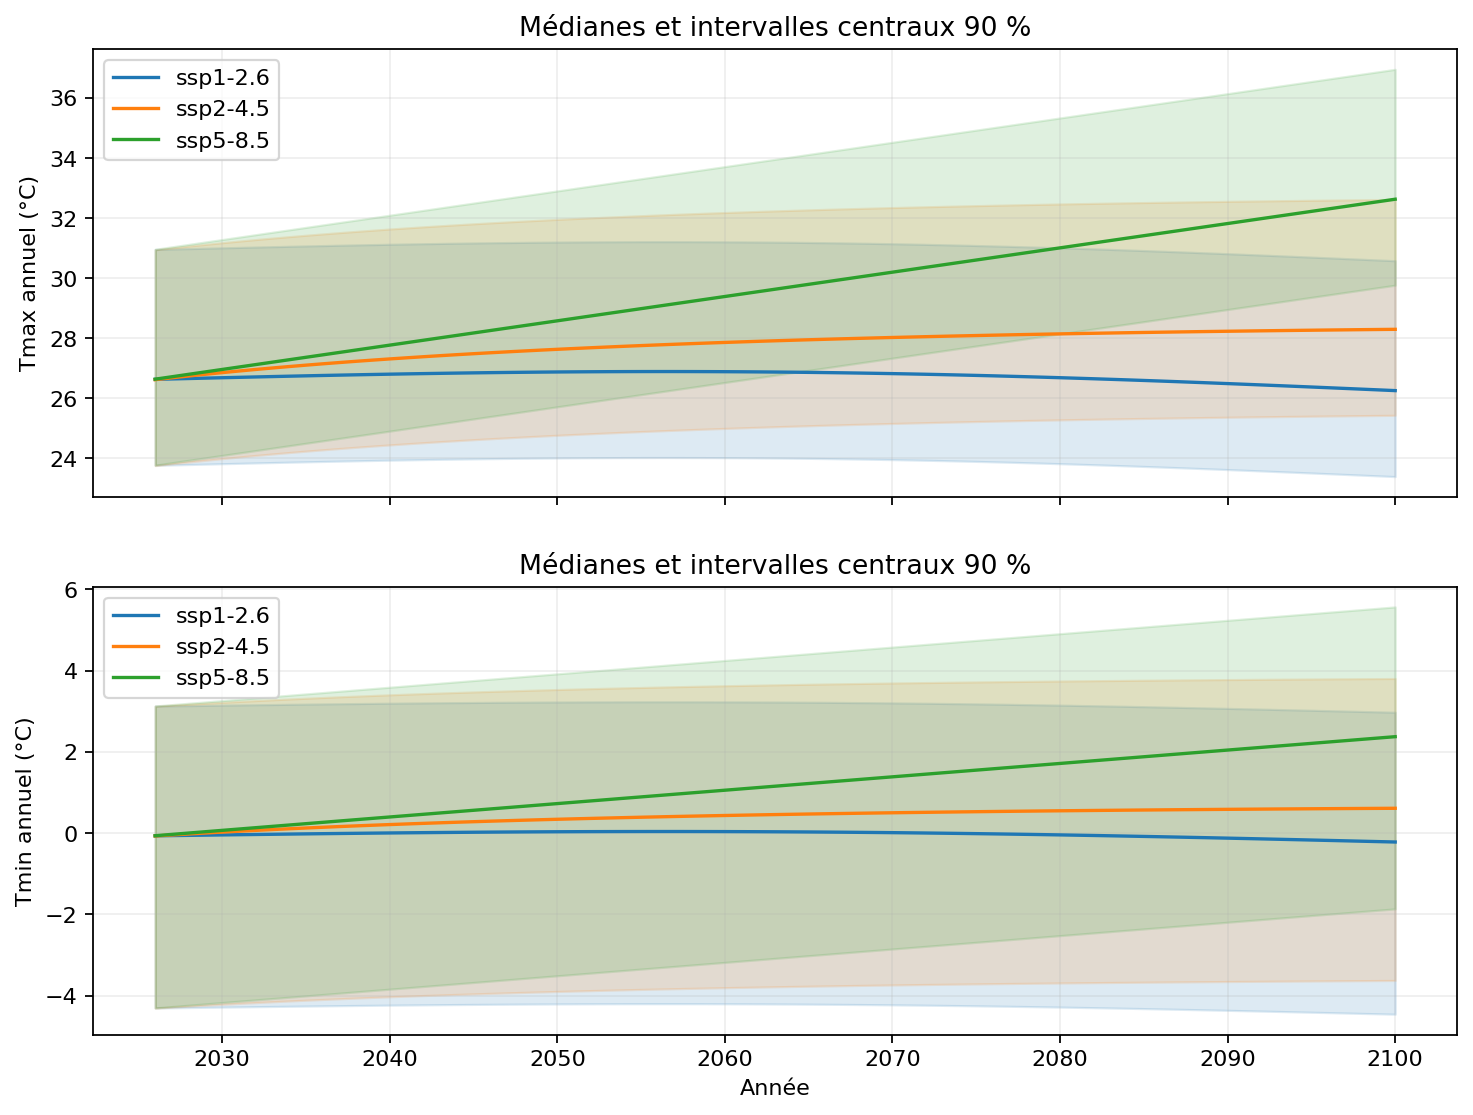

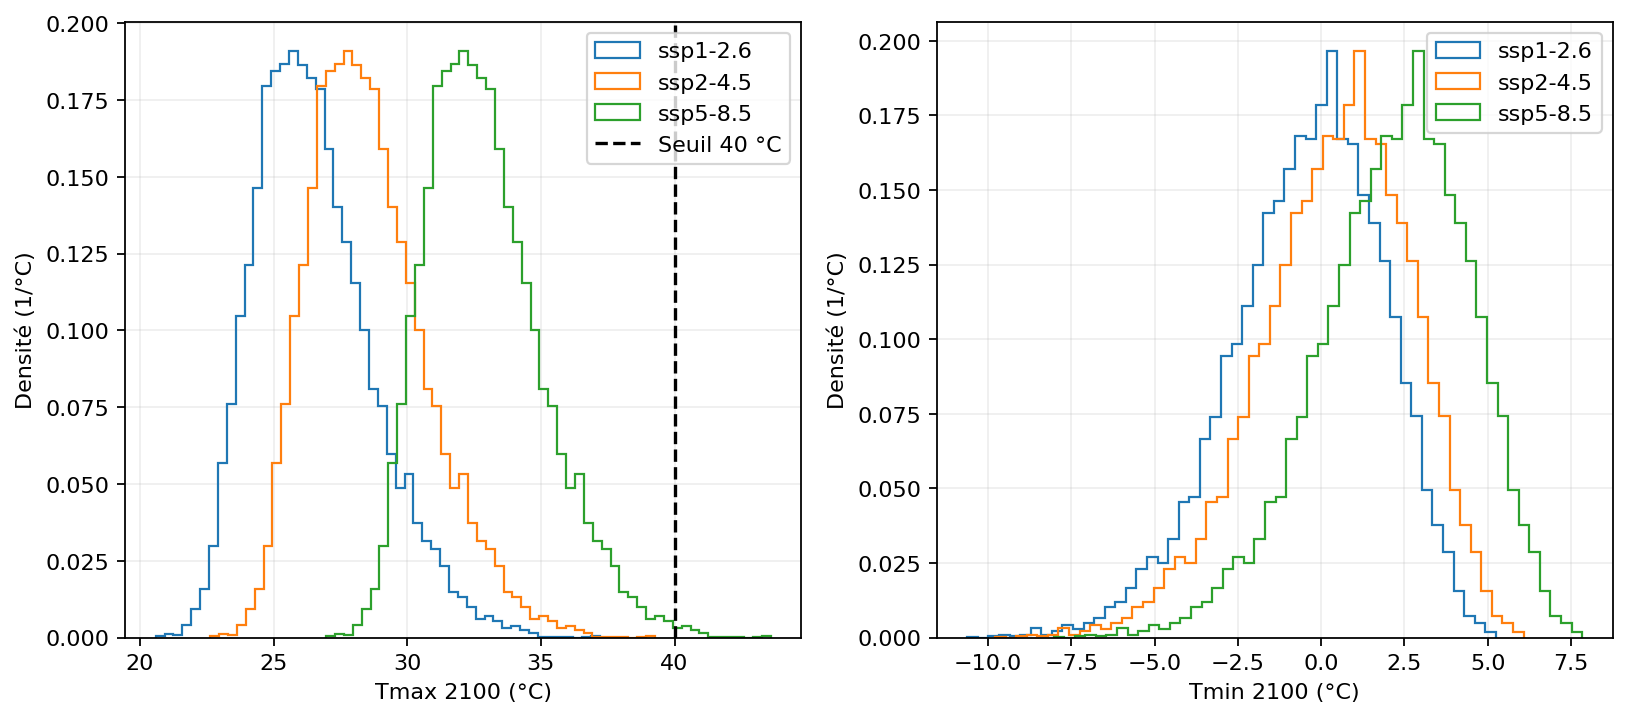

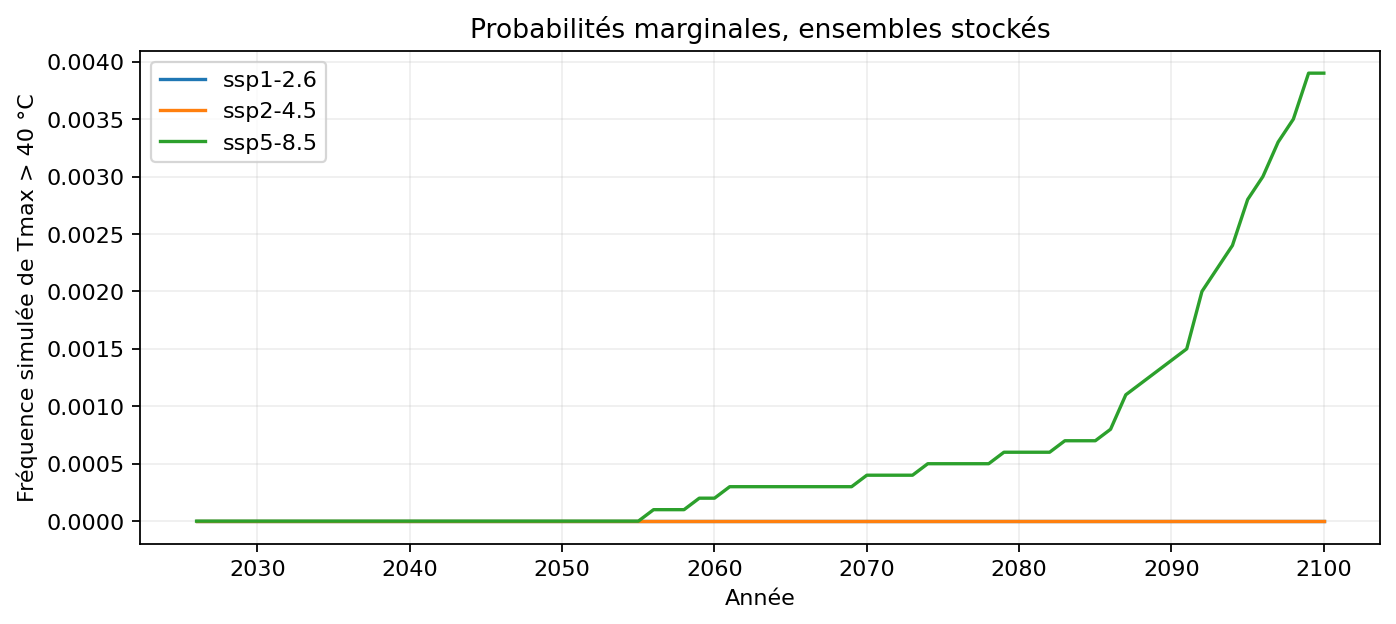

In [13]:
residuals_full = show_residuals('full_project')
projections = show_csv(FULL / 'projection_summary.csv', 12)
show_projected_events()
probability_40 = show_csv(FULL / 'probability_40.csv')
trajectory_40 = show_csv(FULL / 'trajectory_probability_40.csv')
transition = show_json(FULL / 'co2_transition.json')
show_figures('full_project', ['projection_trajectories', 'projection_distributions_2100', 'projection_probability_40_annual'])

## Journal et discussion des résultats réellement obtenus

In [14]:
for report in ['rapport_competition.md', 'rapport_projections.md', 'synthese_equipe.md']:
    path = ROOT / 'reports' / report
    if path.exists():
        display(Markdown(f'Rapport complet : `{path.relative_to(ROOT)}`'))
        if report == 'synthese_equipe.md':
            display(Markdown(path.read_text(encoding='utf-8')))

Rapport complet : `reports\rapport_competition.md`

Rapport complet : `reports\rapport_projections.md`

Rapport complet : `reports\synthese_equipe.md`

# Synthèse équipe


Candidat verrouillé : Tmax **C0_direct_crps**, Tmin **D1_ddm_crps**. Les choix sont fixés sur validation 1940–2000 avant ouverture du test.


Résultats réels du benchmark (°C pour les CRPS) :


| model | crps_max | crps_min | admissible | errors |
| --- | --- | --- | --- | --- |
| R0_exact | 1.69889 | 1.06413 | True | — |
| R0_gaussian | 1.70769 | 1.06449 | True | — |
| R1_gev | 1.7278 | 1.03603 | True | — |
| R2_empirical | 1.735 | 1.03015 | True | — |
| D0_ddpm | 1.75006 | 2.62 | False | min: bornes |
| C0_direct_crps | 1.74899 | 1.02704 | True | — |
| D1_ddm_crps | 1.70071 | 1.03104 | True | — |
| D2_ddm_tail | 1.70691 | 1.01464 | True | — |
| D3_ddm_anchor | 1.64919 | 0.987842 | True | — |
| D4_ddm_tail_anchor | 1.65476 | 0.978821 | True | — |
| participant | 1.74899 | 1.03104 | True | — |


Participant **participant** : CRPS Tmax **1.748986 °C**, Tmin **1.031040 °C** ; statut **admissible**.

**DDPM D0 est éliminé** : 19152 valeurs de Tmin sortent de [−30,20] °C ; le minimum simulé atteint **-1933.216 °C**. Son CRPS Tmin brut est **2.619998 °C** et le kit retourne None. Un bon score de validation ne rend donc pas cette configuration admissible.

Détails : [diagnostic_echec_ddpm.md](diagnostic_echec_ddpm.md), fondé sur le NPZ et les checkpoints figés.


Tmax > 40 °C en 2100, conditionnellement au modèle : ssp1-2.6 **0/10000 (0.000 %)**; ssp2-4.5 **2/10000 (0.020 %)**; ssp5-8.5 **29/10000 (0.290 %)**. Avec zéro tirage dépassant 40 °C, aucun dépassement n'est simulé ; la borne Monte-Carlo à 95 % est 0,000369, pas une probabilité physique nulle.


Vagues de chaleur descriptives 1940–2025 : **421 événements ≥ 3 jours**, **798 ≥ 2 jours** ; durée maximale **14 jours**.


Les 25 années de test et les 61 années d'apprentissage limitent la précision des conclusions. Le CO₂ sert de covariable de tendance ; la stabilité des résidus et l'extrapolation jusqu'à 2100 restent des hypothèses. La simulation de 40 °C ne valide pas la queue physique.


À partager localement : les deux rapports, les notebooks exécutés, les PNG/SVG, les CSV/JSON et les NPZ officiels ; conserver configs, checkpoints et empreintes pour reproduction.


## Références méthodologiques

- [DDPM](https://arxiv.org/abs/2006.11239) et [calendrier cosinus](https://arxiv.org/abs/2102.09672).
- [Diffusion et scores probabilistes météo, prépublication](https://arxiv.org/html/2609.38632v1) ; adaptation scalaire explicitée ci-dessus.
- [AIFS-CRPS](https://arxiv.org/html/2412.15832v1) et [estimateurs CRPS](https://scoringrules.readthedocs.io/en/latest/crps_estimators.html).
- [Scores pondérés](https://scoringrules.readthedocs.io/en/latest/weighted_scores.html).
- [GEV et covariable CO₂](https://ascmo.copernicus.org/articles/9/45/2023/).
- [Validation chronologique](https://otexts.com/fpp3/tscv.html).

Ces références méthodologiques ne fournissent aucune observation supplémentaire au modèle.

La provenance exacte des CSV n'est pas certifiée par leurs métadonnées. La documentation ECMWF
décrit [ERA5 HRES à environ 31 km](https://confluence.ecmwf.int/pages/viewpage.action?navigatingVersions=true&pageId=78296807)
et [ERA5-Land à environ 9 km](https://www.ecmwf.int/en/era5-land). La mention 9 km du starter
ne suffit donc pas à identifier le produit fourni. Les consultations et leurs limites figurent dans `reports/audit_sources.md`.
